# Thermal Image Acuity Assessment Using a Two-Level Concentric-C Target
## A Simulation-Based Study with Geometry-Based Classical Computer Vision for RoboCup Rescue

**Project:** `thermal-c-acuity` &nbsp;|&nbsp; **Study type:** simulation-based evaluation (no physical thermal-camera data in this notebook)  
**Method:** physics-inspired thermal image simulation + OpenCV + contour geometry + repeated trials — **no machine learning**

> **Abstract.** This notebook investigates how simulated target distance, optical blur, thermal measurement noise, temperature contrast, and spatial / camera resolution affect the ability of a geometry-based classical computer-vision detector to resolve a two-level concentric-C (Landolt-C-like) thermal target. Every experiment isolates one independent variable and is reported with its objective, hypothesis, controlled variables, procedure, results, interpretation and limitation. All results are **simulation results**: they characterise the combined *simulation + preprocessing + detector* system, not a physical thermal camera. A key outcome of the structured re-analysis is that the detector is more fragile than the original headline numbers suggested (see *Reproducibility status* below), which is itself a finding that shapes the next physical experiment.

### Reproducibility status of this revision (read first)

This revision keeps all original code and all original recorded results. It also **re-executes** every experiment inside the notebook so each number can be checked. The outcome is stated openly:

| Experiment | Original notebook | Re-executed here | Status |
|---|---|---|---|
| 1 Distance | Reliable to 0.7 m, fails at 0.8 m (recorded text; code **not** in original) | Detected only at 0.5 m; 0.6 m and 0.7 m fail | **Does not reproduce** from the code available |
| 2 Blur | All 8 kernels detected (recorded text; code **not** in original) | 7 of 8 detected; **5×5 fails** | **Partly reproduces** |
| 3 Noise | 100 % to σ = 3 °C, 75 % at 4 °C (recorded text; code **not** in original) | 100 % to σ = 3 °C, 80 % at 4 °C | **Reproduces within sampling uncertainty** |
| 4 Contrast | 100 % at all contrasts down to 1 °C (recorded text; code **not** in original) | Same, with the adaptive threshold | **Reproduces** |
| 5 Target size | No recorded sweep | New sweep run in this revision | **New** |
| 5B Camera resolution | Markdown says 640×512 = 100 %; the original *code output* says 0/20 | 0/20 at 640×512 (matches the code output, not the markdown) | **Markdown/code conflict in the original; code output reproduces** |

Where the recorded value and the re-run differ, **both are shown and neither is silently replaced.** The re-run values are the ones reproducible from this notebook.

## 1. Research question

**Main question.** *How do distance, optical blur, thermal measurement noise, temperature contrast, and spatial / camera resolution affect the ability to resolve and detect a two-level concentric-C pattern in a thermal image?*

**Why it matters for RoboCup Rescue.** A rescue robot's thermal camera must show not only that *something warm* is present, but also *structure* — shape, opening, orientation. Telling a C from an O requires the imaging chain to preserve a gap that is small compared with the target. That is a statement about **spatial resolving capability** (acuity), which depends jointly on sampling (pixels on target), blur, noise and thermal contrast. A systematic acuity study quantifies how close to those limits a given camera / distance / scene combination operates, instead of relying on "it looks detectable".

**Scope of this notebook.** The question is answered *computationally*. Transferring the answer to a physical camera requires the validation plan in Section 21.

## 2. Motivation

**Why thermal imaging in rescue robotics.** Thermal cameras image emitted long-wave infrared radiation, so they work in darkness, smoke and dust where visible-light cameras fail, and they make warm bodies and heat sources stand out from the background. *(General background; no camera-specific claim is made here.)*

**Why a structured target.** Natural scenes confound many variables at once. A known synthetic/physical target with exact geometric ground truth lets each imaging factor be varied one at a time and scored objectively.

**Why a two-level concentric C.** A Landolt C is a standard acuity optotype: the observer must resolve the *opening*. A complete ring cannot test this. Two concentric levels add two further checks — the levels must share a **centre** and have compatible **opening directions** — which reduces the chance that noise blobs or a single ring pass as a valid target, and provides two different feature scales (ring widths 6 px and 4 px; opening arcs ≈ 23.6 px and ≈ 11.8 px at baseline).

**Why physics + classical image processing, not machine learning.** (i) Every stage is interpretable, so a failure can be traced to a specific stage (Section 7.3 does exactly this). (ii) No training data from a specific camera is needed. (iii) The results characterise the *imaging conditions* rather than the generalisation of a learned model. (iv) The detector's rules are explicit and can be mirrored on the physical target.

## 3. Research hypotheses

Each hypothesis is **falsifiable** and is revisited in the Conclusion (Section 22).

| ID | Variable | Testable hypothesis |
|---|---|---|
| H1 | Distance | Increasing simulated distance reduces the target's pixel footprint ($\propto 1/d$); detection rate falls from ≈100 % to ≈0 % over a finite distance range, with a failure point where the thinnest feature (inner ring) approaches the width of the 3 × 3 morphological kernel. |
| H2 | Blur | Increasing Gaussian blur eventually removes detection, but a threshold + contour detector tolerates moderate blur because thresholding restores a binary edge. Failure is expected when the thin ring's blurred peak falls below the binary threshold. |
| H3 | Thermal noise | Detection stays ≈100 % while simulated noise σ is small relative to the threshold margin and falls sharply once background pixels start to cross the threshold. |
| H4 | Temperature contrast | With an *adaptive* threshold and **no** noise, detection persists to very small contrast; with a *fixed* threshold, detection is lost once ΔT falls below the threshold margin (≈ 4.7 °C). With noise, the usable contrast rises with σ. |
| H5 | Spatial resolution (target size in pixels) | Detection requires a minimum pixel footprint; below it the opening and ring separation are not preserved. A sharp (not gradual) transition may appear because the detector uses hard thresholds. |
| H6 | Camera resolution | Reducing sensor resolution (fixed scene) reduces pixels on target and eventually prevents detection; absolute-pixel detector tolerances may introduce additional resolution-dependent behaviour. |

## 4. System / physical model

The study follows this conceptual pipeline:

```text
Target geometry → Thermal temperature field → Distance scaling → Optical blur → Thermal measurement noise
      → Image preprocessing → Binary image → Contours → Geometric C analysis → Two-level concentric-C detection
```

| Stage | What it represents | Implemented as |
|---|---|---|
| Target geometry | Exact ground-truth shape: two annular rings, each with a 45° opening | `draw_c_mask` (analytic ring ∧ ¬gap) |
| Thermal temperature field | Emitted temperature of target vs. background. Idealised: uniform 40 °C target on uniform 25 °C background | `create_temperature_map` (no emissivity, conduction, or thermal inertia) |
| Distance scaling | Apparent size in the image falls as $1/d$ (pinhole-camera geometry: $s_{img}=f\,S/d$) | `simulate_distance`: crop target bounding box, resize by $0.5/d$ with `INTER_AREA`, paste at image centre |
| Optical blur | Spatial spreading of detail by optics / detector footprint | Gaussian filter (`GaussianBlur`); an **approximation**, not a measured PSF/MTF |
| Thermal measurement noise | Random per-pixel temperature error | i.i.d. zero-mean Gaussian noise in °C (`add_thermal_noise`); **not** a real NETD |
| Image preprocessing | Mapping to display range, binarisation, speckle removal | 8-bit scaling, fixed threshold, 3 × 3 morphological opening |
| Binary image → contours | Region boundaries | `cv2.findContours` |
| Geometric C analysis | Shape descriptors of each contour | area, centroid, enclosing-circle radius, angular-gap scan |
| Detection decision | Rule-based acceptance of a two-level concentric C | centre-distance, radius-ratio, gap-size, gap-direction tests |

Pixel footprint is linked to a physical camera by $N_{px} = S/(d\cdot \mathrm{IFOV})$ (target size $S$, distance $d$, detector instantaneous field of view IFOV). **No IFOV or camera model is assumed in this notebook**, so "distance" here is a *simulation parameter* that rescales the image, not a calibrated range.

### 4.1 Implementation of the model

*Code cells in this section are the original notebook code, kept unchanged; added cells are marked **(new)**. Each cell is preceded by a short description of what it does.*

**Environment and random seed.**

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 2.4.4
OpenCV: 4.13.0
Matplotlib: 3.10.8


**Presentation settings and helpers (new).** Figure style, the trial count (`N_TRIALS = 20`), the 80 % reliability criterion, a Wilson 95 % confidence interval for detection rates, and a helper that runs the unchanged detector repeatedly. These do not alter any detector or simulation behaviour.

In [2]:
# ---- Global figure style (presentation only; no effect on any computation) ----
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "legend.fontsize": 10, "axes.grid": True, "grid.alpha": 0.3,
})
N_TRIALS = 20            # repeated trials per condition (as in the original study)
RELIABILITY = 0.80       # project-level reliability criterion (not a standard)

def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a detection rate k/n."""
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return max(0.0, c - h), min(1.0, c + h)

def detection_count(make_temperature, n=N_TRIALS, **prep):
    """Run the unchanged detector n times; make_temperature(i) returns the i-th input.
    Returns the number of successful detections."""
    k = 0
    for i in range(n):
        t = make_temperature(i)
        img = preprocess(t, **prep)
        if detect_concentric_pair(img) is not None:
            k += 1
    return k

## 5. Target design

### 5.1 Parameters (original values, unchanged)

| Quantity | Symbol | Value |
|---|---|---|
| Image size (reference sensor) | $W\times H$ | 320 × 256 px |
| Background temperature | $T_b$ | 25.0 °C |
| Target temperature | $T_t$ | 40.0 °C (ΔT = 15 °C) |
| Common centre | $(c_x,c_y)$ | $(W/2,\,H/2)=(160,128)$ px |
| Outer C radius (to ring mid-line) / ring width | $r_o,\;w_o$ | 30 px / 6 px |
| Inner C radius (to ring mid-line) / ring width | $r_i,\;w_i$ | 15 px / 4 px |
| Opening (gap) angle | $\alpha$ | 45° (θ from 0° to 45° measured from +x, image y pointing down → opening centred at 22.5°) |
| Radius ratio | $r_o/r_i$ | 2.0 |

### 5.2 Geometry
With $\rho(x,y)=\sqrt{(x-c_x)^2+(y-c_y)^2}$ and $\theta(x,y)=\operatorname{atan2}(y-c_y,\,x-c_x)\bmod 360^\circ$, each C is

$$ C(r,w)=\Big\{(x,y):\ r-\tfrac{w}{2}\le\rho\le r+\tfrac{w}{2}\Big\}\ \setminus\ \Big\{(x,y):\ 0^\circ\le\theta\le\alpha\Big\},\qquad \text{Target}=C(r_o,w_o)\cup C(r_i,w_i). $$

Resulting radial extents: outer ring $27\le\rho\le33$ px, inner ring $13\le\rho\le17$ px, leaving a 10 px radial clearance. The opening's arc length at the ring mid-line is $\alpha\cdot r = 23.6$ px (outer) and 11.8 px (inner). The two Cs share centre **and** opening direction by construction.

### 5.3 Threshold and 8-bit mapping
Temperatures are linearly mapped $[25,40]\,^\circ\mathrm C\to[0,255]$ (0.059 °C per grey level). The binary threshold of 80/255 corresponds to $T_{thr}=25+\tfrac{80}{255}\cdot 15=29.71\,^\circ$C, i.e. a **margin of 4.71 °C above background and 10.29 °C below the target**.

In [3]:
WIDTH, HEIGHT = 320, 256

BACKGROUND_TEMP = 25.0
TARGET_TEMP = 40.0
CONTRAST = TARGET_TEMP - BACKGROUND_TEMP

CX, CY = WIDTH // 2, HEIGHT // 2

OUTER_RADIUS, OUTER_WIDTH = 30.0, 6.0
INNER_RADIUS, INNER_WIDTH = 15.0, 4.0
GAP_ANGLE = 45.0

THRESHOLD = 80
KERNEL_SIZE = 3

print(f"Scene: {WIDTH} × {HEIGHT} pixels")
print(f"Background: {BACKGROUND_TEMP:.1f} °C")
print(f"Target: {TARGET_TEMP:.1f} °C")
print(f"Contrast: {CONTRAST:.1f} °C")

Scene: 320 × 256 pixels
Background: 25.0 °C
Target: 40.0 °C
Contrast: 15.0 °C


**Geometry generator** (original). `draw_c_mask` implements the equation above; `make_two_level_c_mask` forms the union of the two Cs.

In [4]:
def draw_c_mask(cx, cy, radius, width, gap_angle=45.0,
                height=HEIGHT, width_img=WIDTH):
    y, x = np.ogrid[:height, :width_img]

    distance = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

    ring = (
        (distance >= radius - width / 2) &
        (distance <= radius + width / 2)
    )

    angle = np.degrees(np.arctan2(y - cy, x - cx))
    angle = (angle + 360.0) % 360.0

    gap = (angle >= 0.0) & (angle <= gap_angle)

    return ring & ~gap


def make_two_level_c_mask():
    outer = draw_c_mask(CX, CY, OUTER_RADIUS, OUTER_WIDTH)
    inner = draw_c_mask(CX, CY, INNER_RADIUS, INNER_WIDTH)
    return outer | inner

**Temperature field** (original functions). `create_temperature_map` assigns 25 °C / 40 °C; `temperature_to_uint8` performs the linear 8-bit mapping.

In [5]:
def create_temperature_map(
    width=WIDTH,
    height=HEIGHT,
    outer_radius=OUTER_RADIUS,
    inner_radius=INNER_RADIUS,
    outer_width=OUTER_WIDTH,
    inner_width=INNER_WIDTH,
    background_temp=BACKGROUND_TEMP,
    target_temp=TARGET_TEMP
):
    temperature = np.full(
        (height, width),
        background_temp,
        dtype=np.float32
    )

    cx = width // 2
    cy = height // 2

    outer = draw_c_mask(
        cx, cy, outer_radius, outer_width,
        height=height, width_img=width
    )

    inner = draw_c_mask(
        cx, cy, inner_radius, inner_width,
        height=height, width_img=width
    )

    temperature[outer | inner] = target_temp
    return temperature


def temperature_to_uint8(
    temperature,
    min_temp=BACKGROUND_TEMP,
    max_temp=TARGET_TEMP
):
    normalized = (temperature - min_temp) / (max_temp - min_temp)
    normalized = np.clip(normalized, 0, 1)
    return (normalized * 255).astype(np.uint8)

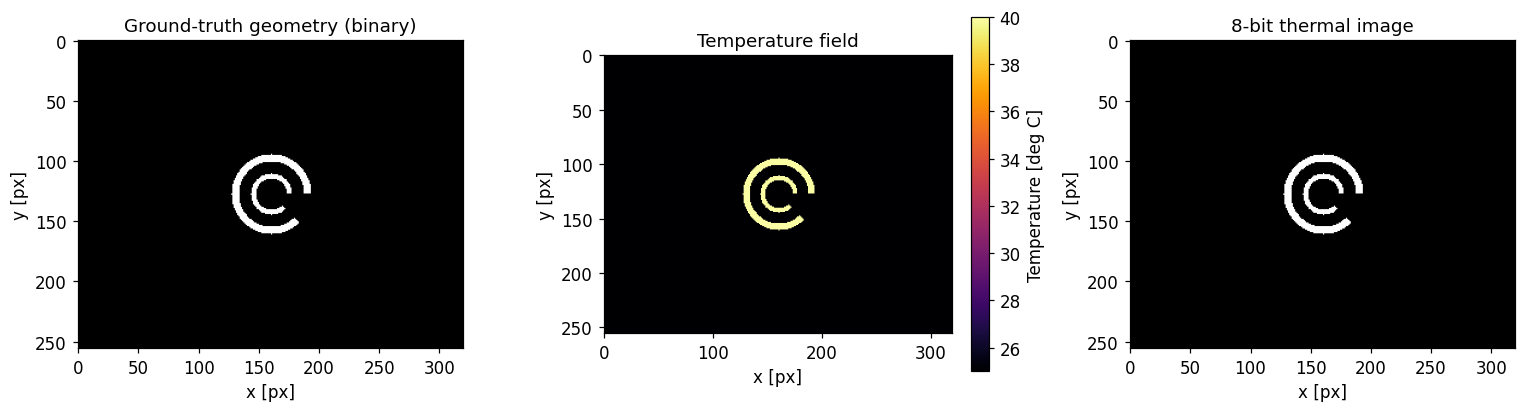

In [6]:
# (new) Build the reference scene used by every experiment and display the ground truth.
target_mask = make_two_level_c_mask()
target_bitmap = (target_mask * 255).astype(np.uint8)
temperature = create_temperature_map()
thermal_image = temperature_to_uint8(temperature)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].imshow(target_bitmap, cmap="gray"); ax[0].set_title("Ground-truth geometry (binary)")
im = ax[1].imshow(temperature, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); ax[1].set_title("Temperature field")
plt.colorbar(im, ax=ax[1], fraction=0.046, label="Temperature [deg C]")
ax[2].imshow(thermal_image, cmap="gray"); ax[2].set_title("8-bit thermal image")
for a in ax: a.set(xlabel="x [px]", ylabel="y [px]"); a.grid(False)
plt.tight_layout(); plt.show()

**Figure 1.** Reference target (320 × 256 px). *Left:* ground-truth binary geometry of the two-level concentric C; both openings face the lower-right (centre at 22.5°, image y downward). *Centre:* idealised temperature field, 25 °C background and 40 °C target. *Right:* 8-bit image the preprocessing stage receives. The model is deliberately simple so that individual degradations can be studied separately.

### 5.4 Distance scaling, blur and noise models (original code)

`simulate_distance` rescales the target's bounding box by $0.5/d$ (reference distance 0.5 m) using area interpolation. `simulate_blur` applies Gaussian blur with $\sigma(d)=\max\!\big(0.1,\;0.5+0.8\,(d-0.5)\big)$ px, used only by the **combined** simulation. `add_thermal_noise` adds $N(0,\sigma^2)$ in °C. The constants `BASE_BLUR_SIGMA` and `BLUR_PER_METER` are *assumed simulation parameters, not measured*.

In [7]:
REFERENCE_DISTANCE = 0.5
BASE_BLUR_SIGMA = 0.5
BLUR_PER_METER = 0.8


def simulate_distance(temperature, distance):
    height, width = temperature.shape
    scale = REFERENCE_DISTANCE / distance

    target_mask = temperature > BACKGROUND_TEMP
    ys, xs = np.where(target_mask)

    if len(xs) == 0:
        return temperature.copy()

    target = temperature[
        ys.min():ys.max() + 1,
        xs.min():xs.max() + 1
    ]

    new_w = max(2, int(target.shape[1] * scale))
    new_h = max(2, int(target.shape[0] * scale))

    resized = cv2.resize(
        target,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    result = np.full(
        (height, width),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    start_x = width // 2 - new_w // 2
    start_y = height // 2 - new_h // 2

    end_x = start_x + new_w
    end_y = start_y + new_h

    sx1, sy1, sx2, sy2 = 0, 0, new_w, new_h
    dx1, dy1, dx2, dy2 = start_x, start_y, end_x, end_y

    if dx1 < 0:
        sx1, dx1 = -dx1, 0
    if dy1 < 0:
        sy1, dy1 = -dy1, 0
    if dx2 > width:
        sx2 -= dx2 - width
        dx2 = width
    if dy2 > height:
        sy2 -= dy2 - height
        dy2 = height

    result[dy1:dy2, dx1:dx2] = resized[sy1:sy2, sx1:sx2]
    return result


def simulate_blur(temperature, distance):
    sigma = (
        BASE_BLUR_SIGMA +
        BLUR_PER_METER * (distance - REFERENCE_DISTANCE)
    )
    sigma = max(0.1, sigma)

    return cv2.GaussianBlur(
        temperature,
        (0, 0),
        sigmaX=sigma,
        sigmaY=sigma
    )

In [8]:
def add_thermal_noise(temperature, noise_sigma, generator=None):
    if generator is None:
        generator = np.random.default_rng()

    noise = generator.normal(
        0,
        noise_sigma,
        temperature.shape
    )

    return (temperature + noise).astype(np.float32)

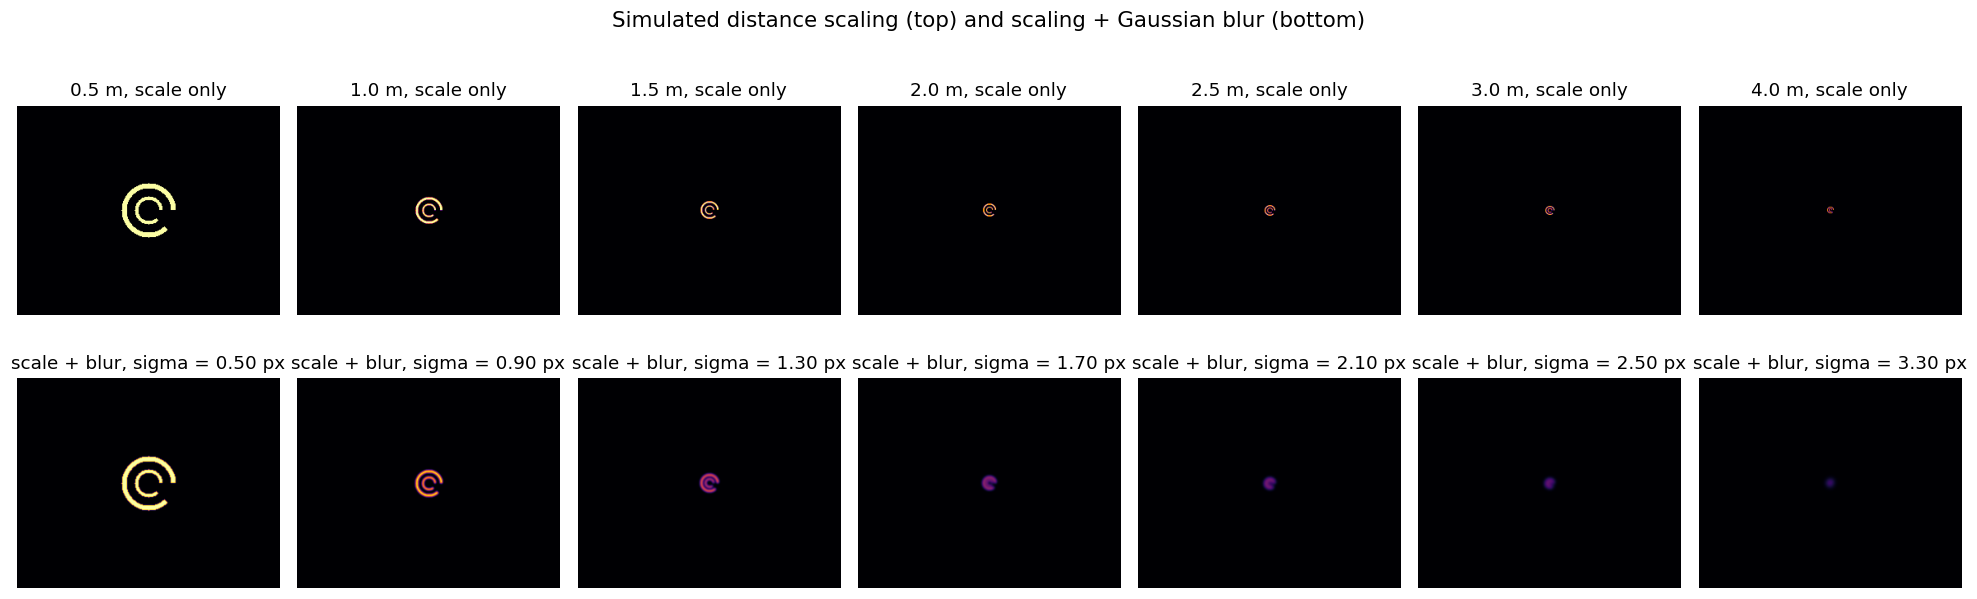

In [9]:
# (new) Visual check of the original distance-and-blur model.
distances = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]
fig, axes = plt.subplots(2, len(distances), figsize=(18, 6))
for i, d in enumerate(distances):
    scaled = simulate_distance(temperature, d)
    sigma = max(0.1, BASE_BLUR_SIGMA + BLUR_PER_METER * (d - REFERENCE_DISTANCE))
    axes[0, i].imshow(scaled, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); axes[0, i].set_title(f"{d:.1f} m, scale only")
    axes[1, i].imshow(simulate_blur(scaled, d), cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); axes[1, i].set_title(f"scale + blur, sigma = {sigma:.2f} px")
    axes[0, i].axis("off"); axes[1, i].axis("off")
fig.suptitle("Simulated distance scaling (top) and scaling + Gaussian blur (bottom)", fontsize=14)
plt.tight_layout(); plt.show()

**Figure 2.** Simulated appearance of the target at increasing distance (columns). *Top:* pure image-space scaling — the target shrinks as $1/d$. *Bottom:* scaling plus the assumed distance-dependent Gaussian blur (σ in pixels). Distances are simulation parameters, not calibrated ranges.

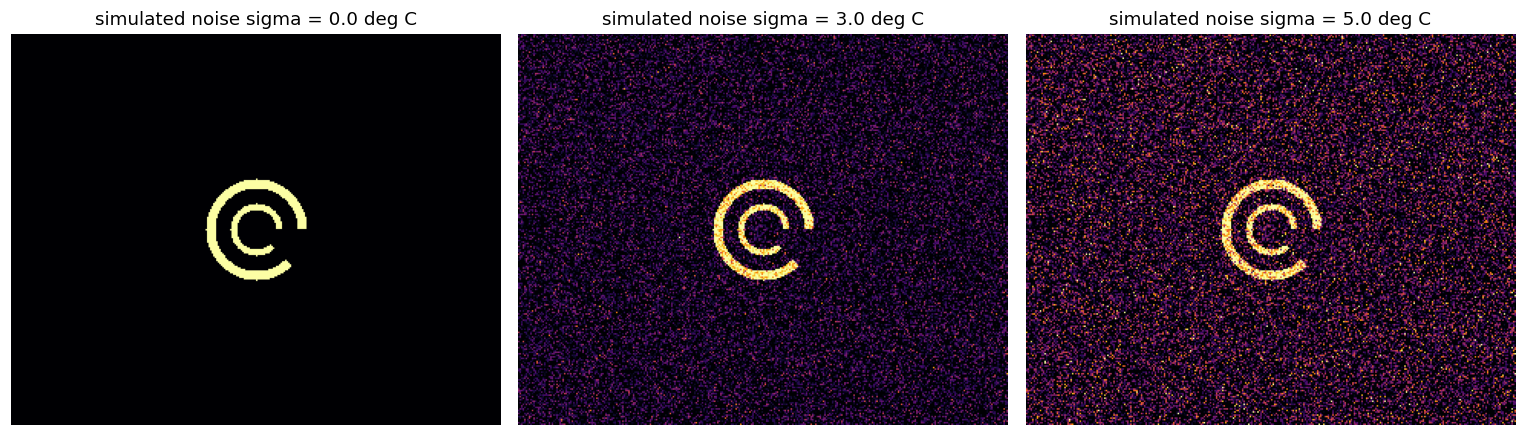

In [10]:
# (new) Effect of simulated Gaussian noise on the reference scene.
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for a, s in zip(ax, [0.0, 3.0, 5.0]):
    a.imshow(add_thermal_noise(temperature, s, np.random.default_rng(RNG_SEED)), cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    a.set_title(f"simulated noise sigma = {s} deg C"); a.axis("off")
plt.tight_layout(); plt.show()

**Figure 3.** The reference scene with zero-mean Gaussian temperature noise of σ = 0, 3 and 5 °C (same seed, 42). Note that the colour scale is held fixed at 25–40 °C. This is a simulated-noise abstraction, not a camera noise model.

## 6. Classical computer-vision detector (geometry-based, not ML)

The detector is a deterministic rule-based pipeline. **No parameters are learned.**

| Step | Operation (code) | Purpose / physical meaning |
|---|---|---|
| 1 Thresholding | `cv2.threshold` at 80/255 (≈ 29.7 °C for the 25–40 °C range) | Separates "hot" from "background" pixels |
| 2 Morphological processing | 3 × 3 opening (erosion then dilation) | Removes isolated speckle; also removes any structure thinner than ≈ 3 px |
| 3 Contour extraction | `cv2.findContours`, `RETR_TREE` | Region boundaries |
| 4 Contour area | `cv2.contourArea`; contours with area ≤ 2 px² discarded | Noise-blob rejection |
| 5 Center estimation | Contour centroid from image moments | Candidate ring centre |
| 6 Radius estimation | Radius of `cv2.minEnclosingCircle` | Candidate ring radius |
| 7 Center-distance test | centroid distance ≤ `CENTER_TOLERANCE` = 5.0 px | Concentricity (absolute pixels) |
| 8 Radius-ratio test | larger/smaller radius ≥ `RADIUS_RATIO_MIN` = 1.30 | Two distinct levels |
| 9 Angular gap detection | 360 angular samples; at each angle 7 radial samples in $r\pm2$ px; longest run of empty angles | Opening width of each ring |
| 10 Gap direction | centre of that longest empty run | Orientation of each opening |
| 11 Final decision | both gaps ≥ `MIN_GAP_ANGLE` = 20° **and** direction difference ≤ `GAP_DIRECTION_TOLERANCE` = 30° | Two-level concentric C accepted |

Pairs of contours are examined; the first pair that passes all tests produces a positive detection.

In [11]:
CENTER_TOLERANCE = 5.0
RADIUS_RATIO_MIN = 1.30
MIN_GAP_ANGLE = 20.0
GAP_DIRECTION_TOLERANCE = 30.0


def find_contour_candidates(binary_image):
    contours, _ = cv2.findContours(
        binary_image,
        cv2.RETR_TREE,
        cv2.CHAIN_APPROX_SIMPLE
    )

    candidates = []

    for contour in contours:
        area = cv2.contourArea(contour)

        if area <= 2:
            continue

        M = cv2.moments(contour)

        if M["m00"] == 0:
            continue

        center = np.array([
            M["m10"] / M["m00"],
            M["m01"] / M["m00"]
        ])

        (_, _), radius = cv2.minEnclosingCircle(contour)

        candidates.append({
            "contour": contour,
            "area": area,
            "center": center,
            "radius": radius
        })

    return candidates


def find_image_angular_gap(binary_image, center, radius, num_angles=360):
    height, width = binary_image.shape
    angles = np.linspace(0, 360, num_angles, endpoint=False)
    occupied = np.zeros(num_angles, dtype=bool)

    for i, angle in enumerate(angles):
        theta = np.radians(angle)
        found = False

        for r in np.linspace(
            max(1, radius - 2),
            radius + 2,
            7
        ):
            x = int(round(center[0] + r * np.cos(theta)))
            y = int(round(center[1] + r * np.sin(theta)))

            if 0 <= x < width and 0 <= y < height:
                if binary_image[y, x] > 0:
                    found = True
                    break

        occupied[i] = found

    circular = np.concatenate([occupied, occupied])

    longest_empty = 0
    current_empty = 0
    longest_end = 0

    for i, value in enumerate(circular):
        if not value:
            current_empty += 1
            if current_empty > longest_empty:
                longest_empty = current_empty
                longest_end = i
        else:
            current_empty = 0

    longest_empty = min(longest_empty, num_angles)

    gap_angle = longest_empty * 360.0 / num_angles

    gap_center_index = (
        longest_end - longest_empty / 2
    ) % num_angles

    gap_center_angle = (
        gap_center_index * 360.0 / num_angles
    )

    return gap_angle, gap_center_angle


def detect_concentric_pair(binary_image):
    candidates = find_contour_candidates(binary_image)

    if len(candidates) < 2:
        return None

    for i in range(len(candidates)):
        for j in range(i + 1, len(candidates)):

            c1 = candidates[i]
            c2 = candidates[j]

            center_distance = np.linalg.norm(
                c1["center"] - c2["center"]
            )

            larger = max(c1["radius"], c2["radius"])
            smaller = min(c1["radius"], c2["radius"])

            if smaller <= 0:
                continue

            radius_ratio = larger / smaller

            if center_distance > CENTER_TOLERANCE:
                continue

            if radius_ratio < RADIUS_RATIO_MIN:
                continue

            outer = c1 if c1["radius"] >= c2["radius"] else c2
            inner = c2 if outer is c1 else c1

            outer_gap, outer_direction = find_image_angular_gap(
                binary_image, outer["center"], outer["radius"]
            )

            inner_gap, inner_direction = find_image_angular_gap(
                binary_image, inner["center"], inner["radius"]
            )

            if (
                outer_gap < MIN_GAP_ANGLE or
                inner_gap < MIN_GAP_ANGLE
            ):
                continue

            direction_difference = abs(
                outer_direction - inner_direction
            )
            direction_difference = min(
                direction_difference,
                360 - direction_difference
            )

            if direction_difference <= GAP_DIRECTION_TOLERANCE:
                return {
                    "outer": outer,
                    "inner": inner,
                    "center_distance": center_distance,
                    "radius_ratio": radius_ratio,
                    "outer_gap_angle": outer_gap,
                    "inner_gap_angle": inner_gap,
                    "outer_gap_direction": outer_direction,
                    "inner_gap_direction": inner_direction,
                    "gap_direction_difference": direction_difference
                }

    return None


def run_detector(temperature):
    cleaned = preprocess(temperature)
    result = detect_concentric_pair(cleaned)
    return result, cleaned

**Preprocessing function** (original): 8-bit mapping → threshold → 3 × 3 opening.

In [12]:
def preprocess(
    temperature,
    min_temp=BACKGROUND_TEMP,
    max_temp=TARGET_TEMP,
    threshold=THRESHOLD,
    kernel_size=KERNEL_SIZE
):
    image = temperature_to_uint8(
        temperature,
        min_temp,
        max_temp
    )

    _, binary = cv2.threshold(
        image,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    kernel = np.ones(
        (kernel_size, kernel_size),
        np.uint8
    )

    return cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

**Baseline detection on the reference scene** (original demo), followed by a figure of the preprocessing stages.

In [13]:
result, cleaned = run_detector(temperature)

print("Detected:", result is not None)

if result is not None:
    print("Outer radius:", result["outer"]["radius"])
    print("Inner radius:", result["inner"]["radius"])
    print("Center distance:", result["center_distance"])
    print("Radius ratio:", result["radius_ratio"])
    print("Outer gap:", result["outer_gap_angle"])
    print("Inner gap:", result["inner_gap_angle"])

Detected: True
Outer radius: 32.98494338989258
Inner radius: 17.000099182128906
Center distance: 2.104478148074601
Radius ratio: 1.940279467579077
Outer gap: 142.0
Inner gap: 47.0


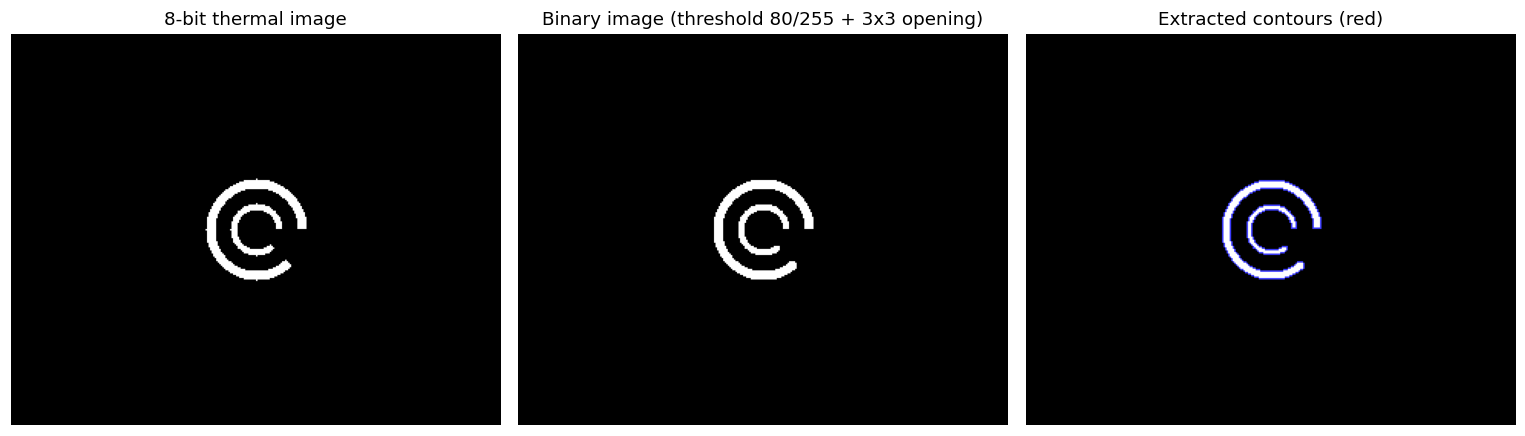

In [14]:
# (new) Preprocessing stages for the reference scene with the detected contours.
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].imshow(thermal_image, cmap="gray"); ax[0].set_title("8-bit thermal image")
ax[1].imshow(cleaned, cmap="gray"); ax[1].set_title("Binary image (threshold 80/255 + 3x3 opening)")
vis = cv2.cvtColor(cleaned, cv2.COLOR_GRAY2BGR)
for c in find_contour_candidates(cleaned): cv2.drawContours(vis, [c["contour"]], -1, (255, 60, 60), 1)
ax[2].imshow(vis[..., ::-1]); ax[2].set_title("Extracted contours (red)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Figure 4.** Detector stages on the reference scene. The detector finds two contours (the outer and inner C) whose centroid separation is 2.1 px (< 5 px tolerance) and radius ratio 1.94 (> 1.3). Reported "outer radius ≈ 33.0 px / inner ≈ 17.0 px" are *enclosing-circle* radii (≈ ring mid-line + half-width + 0–1 px), not the mid-line radii 30 / 15 px.

### 6.1 Failure-mode diagnostic (new, read-only)

`diagnose` re-applies the detector's own tests in the same order and reports **which test rejects an image**. It changes no parameter and no result; it exists so that every failure can be explained rather than just counted.

In [15]:
# Read-only diagnostic: reports WHICH detector test rejects an image. It repeats the detector's own tests in the same order
# and does not change any detector parameter or any reported result.
def diagnose(binary_image):
    cands = find_contour_candidates(binary_image)
    if len(cands) < 2:
        return "fewer than 2 contours", None
    furthest = "no pair passes centre/radius-ratio test"
    info = None
    for i in range(len(cands)):
        for j in range(i + 1, len(cands)):
            c1, c2 = cands[i], cands[j]
            big, small = max(c1["radius"], c2["radius"]), min(c1["radius"], c2["radius"])
            if small <= 0 or np.linalg.norm(c1["center"] - c2["center"]) > CENTER_TOLERANCE or big / small < RADIUS_RATIO_MIN:
                continue
            o, n = (c1, c2) if c1["radius"] >= c2["radius"] else (c2, c1)
            og, od = find_image_angular_gap(binary_image, o["center"], o["radius"])
            ig, idr = find_image_angular_gap(binary_image, n["center"], n["radius"])
            if og < MIN_GAP_ANGLE or ig < MIN_GAP_ANGLE:
                furthest = "gap below MIN_GAP_ANGLE"; continue
            dd = abs(od - idr); dd = min(dd, 360 - dd)
            info = dict(outer_dir=od, inner_dir=idr, diff=dd)
            if dd <= GAP_DIRECTION_TOLERANCE:
                return "detected", info
            furthest = f"gap-direction mismatch ({dd:.0f} deg > {GAP_DIRECTION_TOLERANCE:.0f} deg)"
    return furthest, info

### 6.2 Known behaviour of the detector's centre and gap estimates (new diagnostic — important)

The detector estimates each ring's centre as the **centroid of the contour**. The centroid of a C is *not* the centre of its circle: material is missing on the opening side, so the centroid is pulled toward the opposite side. The angular-gap scan is then run around this biased centre. The cell below compares the detector's gap estimate with the known ground truth (opening centre 22.5°, width 45°).

In [16]:
# Detector-estimated opening vs ground truth. Ground truth: the opening spans 0-45 deg, so its centre is 22.5 deg
# (image coordinates, y downward). Only the TRUE centre (CX, CY) is used for the reference measurement.
true_centre = np.array([CX, CY], dtype=float)
b = preprocess(temperature)
cands = sorted(find_contour_candidates(b), key=lambda c: -c["radius"])
print("Ground-truth opening centre: 22.5 deg, width 45 deg\n")
print(f"{'ring':>6} {'centroid offset from true centre [px]':>40} {'direction of offset [deg]':>26}")
for name, c in zip(["outer", "inner"], cands):
    off = c["center"] - true_centre
    print(f"{name:>6} {np.linalg.norm(off):40.2f} {np.degrees(np.arctan2(off[1], off[0])) % 360:26.1f}")
print()
for name, c, R in zip(["outer", "inner"], cands, [OUTER_RADIUS, INNER_RADIUS]):
    g_det = find_image_angular_gap(b, c["center"], c["radius"])
    g_true = find_image_angular_gap(b, true_centre, R)
    print(f"{name}: detector estimate (width, direction) = {g_det}   |   scan at TRUE centre/radius = {g_true}")

Ground-truth opening centre: 22.5 deg, width 45 deg

  ring    centroid offset from true centre [px]  direction of offset [deg]
 outer                                     4.63                      203.0
 inner                                     2.53                      203.6

outer: detector estimate (width, direction) = (142.0, 206.0)   |   scan at TRUE centre/radius = (46.0, 22.0)
inner: detector estimate (width, direction) = (47.0, 184.5)   |   scan at TRUE centre/radius = (47.0, 21.5)


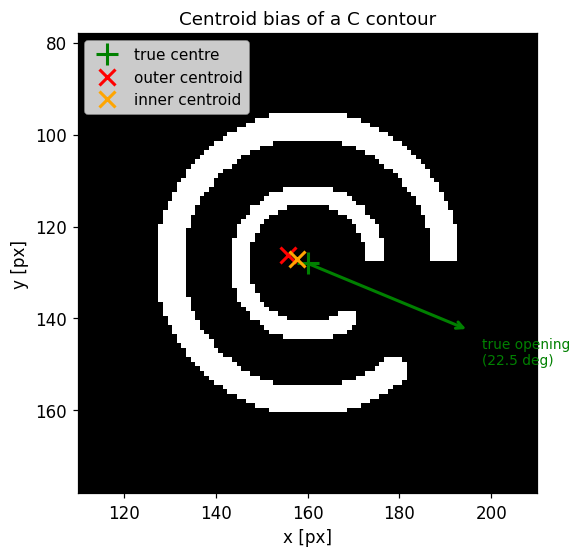

In [17]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.imshow(b, cmap="gray")
ax.plot(*true_centre, "g+", ms=14, mew=2, label="true centre")
for c, col, nm in zip(cands, ["r", "orange"], ["outer centroid", "inner centroid"]):
    ax.plot(*c["center"], "x", color=col, ms=10, mew=2, label=nm)
ax.annotate("", xy=true_centre + 38*np.array([np.cos(np.radians(22.5)), np.sin(np.radians(22.5))]), xytext=true_centre,
            arrowprops=dict(arrowstyle="->", color="g", lw=2))
ax.text(CX + 38, CY + 22, "true opening\n(22.5 deg)", color="g", fontsize=9)
ax.set_xlim(CX-50, CX+50); ax.set_ylim(CY+50, CY-50)
ax.set(title="Centroid bias of a C contour", xlabel="x [px]", ylabel="y [px]"); ax.grid(False); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Figure 5.** Centroid bias. The contour centroids (× markers) are displaced 2.5–4.6 px from the true centre (+), in the direction ≈ 203° — almost exactly opposite the true opening (22.5°).

**Finding.** Scanning at the *true* centre recovers the opening correctly (≈ 46° wide at ≈ 22°). Scanning at the *centroid* gives 142° at 206° (outer) and 47° at 184.5° (inner): the "gap direction" the detector actually compares is dominated by centroid offset, ≈ 180° away from the real opening. At the baseline both rings are biased in the same direction, so the direction-agreement test passes. Consequences, quantified in Experiments 1, 5 and 5B: the success of the baseline detection is **not** direct evidence that the true opening was resolved, and the direction test becomes unreliable when the two rings are biased differently. **The detector has been left unchanged** so that all original results remain interpretable; this is recorded as a limitation and as a priority fix before physical experiments (Section 20).

## 7. Negative control and validation

**Test.** Two complete concentric rings (same radii, widths and temperatures as the target, but **no opening**) are passed through the unchanged detector. A valid detector must **reject** them.

**Why two circles must not count as two Cs.** Acuity is about resolving the *opening*. If two concentric rings were accepted, the detector could succeed at any resolution that merely resolves two blobs, so the acuity result would collapse to "can the rings be seen", which is a much weaker (and easier) criterion than "can the gap be resolved".

In [18]:
def create_two_complete_circles():
    temp = np.full(
        (HEIGHT, WIDTH),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    y, x = np.ogrid[:HEIGHT, :WIDTH]
    distance = np.sqrt(
        (x - CX) ** 2 + (y - CY) ** 2
    )

    outer = (
        (distance >= OUTER_RADIUS - OUTER_WIDTH / 2) &
        (distance <= OUTER_RADIUS + OUTER_WIDTH / 2)
    )

    inner = (
        (distance >= INNER_RADIUS - INNER_WIDTH / 2) &
        (distance <= INNER_RADIUS + INNER_WIDTH / 2)
    )

    temp[outer | inner] = TARGET_TEMP
    return temp

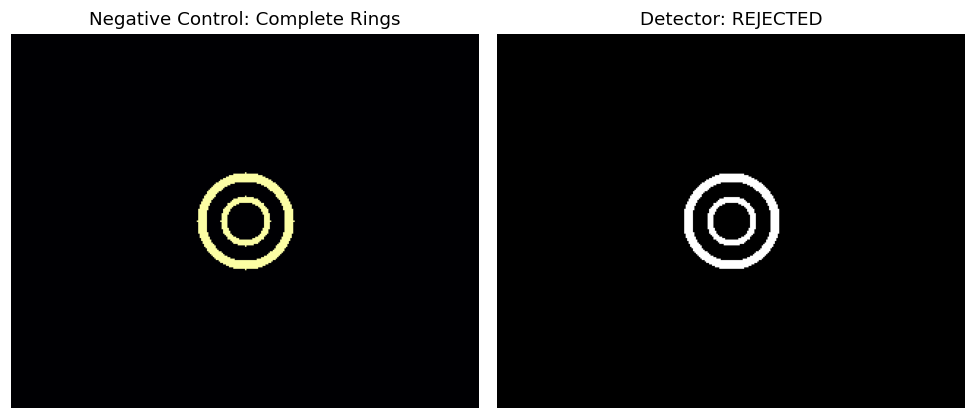

Detected as C: False


In [19]:
circle_temperature = create_two_complete_circles()
circle_result, circle_cleaned = run_detector(circle_temperature)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    circle_temperature,
    cmap="inferno",
    vmin=BACKGROUND_TEMP,
    vmax=TARGET_TEMP
)
axes[0].set_title("Negative Control: Complete Rings")
axes[0].axis("off")

axes[1].imshow(circle_cleaned, cmap="gray")
axes[1].set_title(
    "Detector: " +
    ("DETECTED" if circle_result else "REJECTED")
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Detected as C:", circle_result is not None)

**Figure 6.** Negative control. *Left:* two complete rings. *Right:* binary image and detector outcome — **REJECTED**, as required.

**Additional controls (new).** Three further controls test other ways the detector could be fooled: (NC2) an empty scene with noise only (false-positive rate), (NC3) two Cs with *opposite* openings, (NC4) a single C. A positive control (PC) confirms the same code path accepts the true target.

In [20]:
# Additional negative / sanity controls (new in this revision). Each is run through the UNCHANGED detector.
def flip_c(mask):
    """Rotate a centred mask by 180 deg about (CX, CY) so the opening points the opposite way."""
    return np.roll(mask[::-1, ::-1], (1, 1), axis=(0, 1))

outer_m = draw_c_mask(CX, CY, OUTER_RADIUS, OUTER_WIDTH)
inner_m = draw_c_mask(CX, CY, INNER_RADIUS, INNER_WIDTH)

def scene_from(mask):
    t = np.full((HEIGHT, WIDTH), BACKGROUND_TEMP, dtype=np.float32); t[mask] = TARGET_TEMP; return t

controls = {
    "NC1 two complete rings (original)": scene_from(create_two_complete_circles() > BACKGROUND_TEMP),
    "NC3 outer C + inner C, openings opposite": scene_from(outer_m | flip_c(inner_m)),
    "NC4 single C (outer only)": scene_from(outer_m),
    "PC  two aligned Cs (positive control)": temperature,
}
print(f"{'control':45s} {'detector output':>16}   first failing test")
for name, t in controls.items():
    b_ = preprocess(t); reason, _ = diagnose(b_)
    print(f"{name:45s} {'DETECTED' if detect_concentric_pair(b_) else 'rejected':>16}   {reason}")

# NC2: no target at all, simulated noise only -> false-positive rate over 20 trials per sigma
nc2_rng = np.random.default_rng(RNG_SEED)
blank = np.full((HEIGHT, WIDTH), BACKGROUND_TEMP, dtype=np.float32)
print()
for s in [1.0, 3.0, 5.0, 10.0]:
    fp = sum(detect_concentric_pair(preprocess(add_thermal_noise(blank, s, nc2_rng))) is not None for _ in range(N_TRIALS))
    print(f"NC2 empty scene, noise sigma = {s:4.1f} C -> false detections: {fp}/{N_TRIALS}")

control                                        detector output   first failing test
NC1 two complete rings (original)                     rejected   gap below MIN_GAP_ANGLE
NC3 outer C + inner C, openings opposite              rejected   no pair passes centre/radius-ratio test
NC4 single C (outer only)                             rejected   fewer than 2 contours
PC  two aligned Cs (positive control)                 DETECTED   detected

NC2 empty scene, noise sigma =  1.0 C -> false detections: 0/20
NC2 empty scene, noise sigma =  3.0 C -> false detections: 0/20


NC2 empty scene, noise sigma =  5.0 C -> false detections: 0/20


NC2 empty scene, noise sigma = 10.0 C -> false detections: 0/20


**What the negative controls demonstrate.** (i) Two complete concentric circles are rejected by the gap test (the first failing test is reported above); (ii) the opening is genuinely part of the decision logic; (iii) in the tested conditions an empty noisy scene does not produce false detections (see counts above), and a single C or two opposite-opening Cs are rejected.

**What they do NOT demonstrate.** They do not show that the detector measures the *true* opening (Section 6.2 shows its direction estimate is biased); they cover a small set of impostors only; the false-positive test uses simulated Gaussian noise, not real thermal clutter or hot spots; and they say nothing about sensitivity (that is what Experiments 1–5B probe).

## 8. Experimental methodology

Detection reliability is judged with a **project-level criterion**: a condition is *reliable* if it achieves $\ge 80\,\%$ detection over 20 trials,

$$\text{Detection rate}=\frac{\text{successful detections}}{20}\times100\,\%.$$

This 80 % rule is not a thermal-imaging standard. With 20 trials the uncertainty is large: a 16/20 result has a 95 % Wilson interval of roughly 58–92 %. Intervals are therefore reported for stochastic experiments.

**Deterministic experiments.** Experiments 1, 2, 4 (noiseless), 5 and 5B contain **no random element**: all 20 "trials" yield the identical image and identical outcome, so each is in effect *one* observation repeated 20 times and can only give 0/20 or 20/20. Only the noise-based experiments (3, 4-supplementary, combined) draw independent samples. This must be kept in mind when reading "20/20".

Every experiment below is documented with the same nine headings. Rows labelled *recorded* come from the original notebook's text; the original notebook did **not** contain code for Experiments 1–4, so those were re-implemented here from the documented description (assumptions stated in each Procedure).

## 9. Experiment 1 — Distance

### Objective
Determine how simulated target distance changes detectability when no other degradation is present.

### Hypothesis
(H1) Apparent size ∝ 1/d; detection fails once the thinnest feature (inner ring, 4 px at 0.5 m) approaches the 3 px opening kernel and the opening is no longer preserved.

### Controlled Variables
15 °C contrast (25 → 40 °C), 320 × 256 frame, **no blur, no noise**, detector parameters (threshold 80/255, 3 × 3 opening, tolerances) unchanged.

### Independent Variable
Simulated distance $d$ (m) → image scale $0.5/d$ (apparent target size / pixel occupancy).

### Dependent Variable
Detection (success/failure) over 20 trials; apparent ring width and radius in pixels.

### Procedure
`simulate_distance` rescales the target by $0.5/d$ about the image centre; `preprocess` and `detect_concentric_pair` are applied. The original recorded sweep was 0.5–0.9 m+; the sweep is extended to 4.0 m here. *Distance is a simulation parameter, not a calibrated camera range.*

In [21]:
# Experiment 1 - distance only. No blur, no noise. Detector unchanged.
RECORDED_EXP1 = {0.5: 20, 0.6: 20, 0.7: 20, 0.8: 0}   # from the original notebook text; 0.9 m and above: 0%
DIST_SWEEP = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.5, 2.0, 3.0, 4.0]

exp1 = []
for d in DIST_SWEEP:
    scaled = simulate_distance(temperature, d)             # deterministic: same image on every trial
    k = detection_count(lambda i: scaled)
    scale = REFERENCE_DISTANCE / d
    exp1.append(dict(d=d, scale=scale,
                     outer_r=OUTER_RADIUS * scale,
                     outer_w=OUTER_WIDTH * scale,
                     inner_w=INNER_WIDTH * scale,
                     k=k, rec=RECORDED_EXP1.get(d, 0 if d >= 0.9 else None)))

print(f"{'d [m]':>6} {'scale':>6} {'R_out [px]':>10} {'w_out [px]':>10} {'w_in [px]':>9} {'re-run':>8} {'recorded':>9}")
for r in exp1:
    rec = "-" if r['rec'] is None else f"{r['rec']}/20"
    print(f"{r['d']:6.1f} {r['scale']:6.2f} {r['outer_r']:10.1f} {r['outer_w']:10.2f} {r['inner_w']:9.2f} {r['k']:>5}/20 {rec:>9}")

 d [m]  scale R_out [px] w_out [px] w_in [px]   re-run  recorded
   0.5   1.00       30.0       6.00      4.00    20/20     20/20
   0.6   0.83       25.0       5.00      3.33     0/20     20/20
   0.7   0.71       21.4       4.29      2.86     0/20     20/20
   0.8   0.62       18.8       3.75      2.50     0/20      0/20
   0.9   0.56       16.7       3.33      2.22     0/20      0/20
   1.0   0.50       15.0       3.00      2.00     0/20      0/20
   1.5   0.33       10.0       2.00      1.33     0/20      0/20
   2.0   0.25        7.5       1.50      1.00     0/20      0/20
   3.0   0.17        5.0       1.00      0.67     0/20      0/20
   4.0   0.12        3.8       0.75      0.50     0/20      0/20


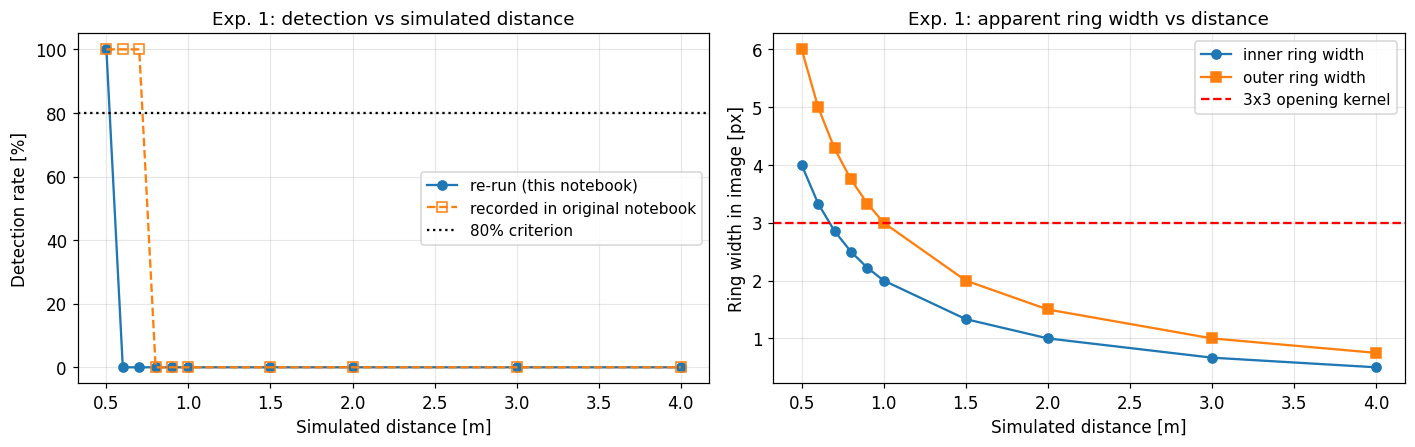

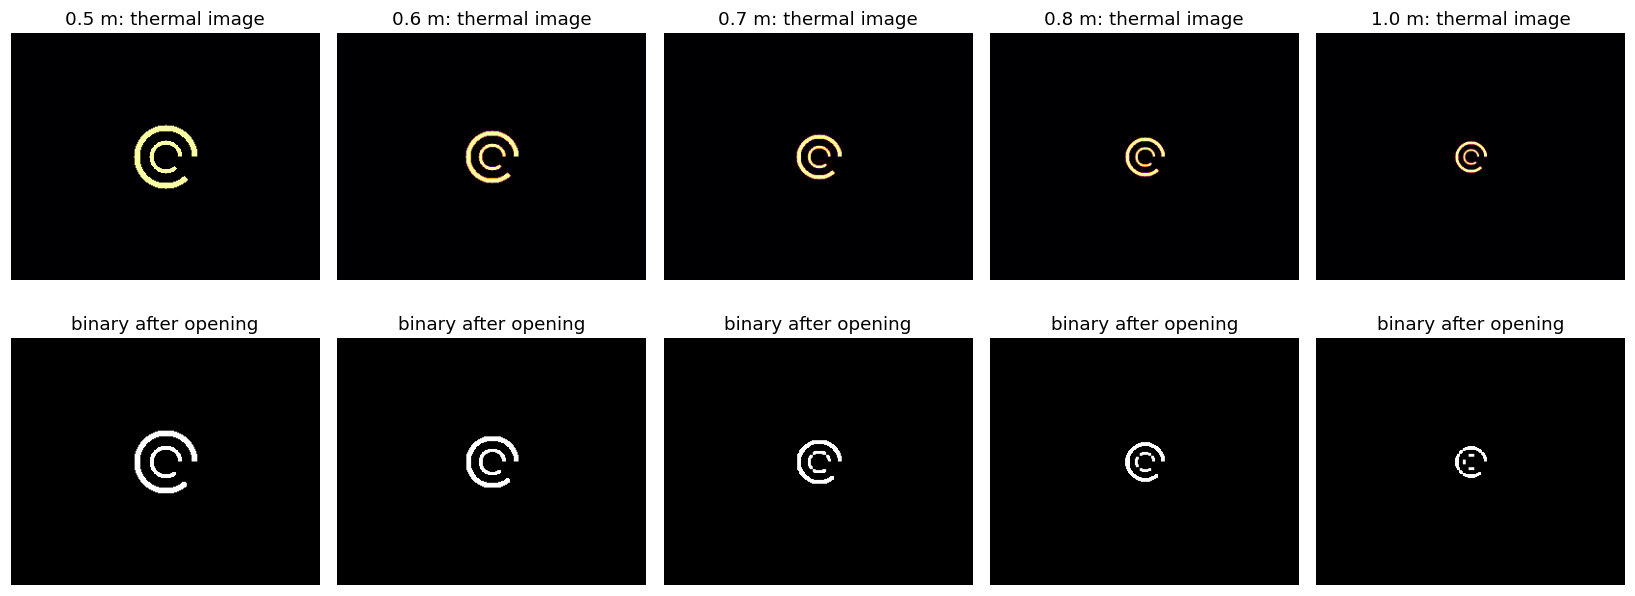

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
d_ = [r['d'] for r in exp1]
ax[0].plot(d_, [100*r['k']/N_TRIALS for r in exp1], "o-", label="re-run (this notebook)")
rec_d = [d for d in d_ if d in RECORDED_EXP1 or d >= 0.9]
ax[0].plot(rec_d, [100*RECORDED_EXP1.get(d, 0)/N_TRIALS for d in rec_d], "s--", mfc="none",
           label="recorded in original notebook")
ax[0].axhline(80, color="k", ls=":", label="80% criterion")
ax[0].set(xlabel="Simulated distance [m]", ylabel="Detection rate [%]", ylim=(-5, 105),
          title="Exp. 1: detection vs simulated distance")
ax[0].legend()

ax[1].plot(d_, [r['inner_w'] for r in exp1], "o-", label="inner ring width")
ax[1].plot(d_, [r['outer_w'] for r in exp1], "s-", label="outer ring width")
ax[1].axhline(KERNEL_SIZE, color="r", ls="--", label=f"{KERNEL_SIZE}x{KERNEL_SIZE} opening kernel")
ax[1].set(xlabel="Simulated distance [m]", ylabel="Ring width in image [px]",
          title="Exp. 1: apparent ring width vs distance")
ax[1].legend()
plt.tight_layout(); plt.show()

show = [0.5, 0.6, 0.7, 0.8, 1.0]
fig, ax = plt.subplots(2, len(show), figsize=(3*len(show), 6))
for j, d in enumerate(show):
    t = simulate_distance(temperature, d)
    ax[0, j].imshow(t, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); ax[0, j].set_title(f"{d} m: thermal image")
    ax[1, j].imshow(preprocess(t), cmap="gray"); ax[1, j].set_title("binary after opening")
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

**Figure 7.** *Left:* detection rate vs. simulated distance, re-run (solid) against the originally recorded result (dashed). *Right:* apparent ring widths vs. distance against the 3 px opening kernel (red). *Below:* thermal and binary images at selected distances.

### Results
| Distance | Scale | Outer R [px] | Inner ring width [px] | **Re-run** | **Recorded** | First failing test (re-run) |
|---:|---:|---:|---:|---:|---:|---|
| 0.5 m | 1.00 | 30.0 | 4.00 | 20/20 | 20/20 | – (detected) |
| 0.6 m | 0.83 | 25.0 | 3.33 | **0/20** | 20/20 | gap-direction mismatch (≈168°) |
| 0.7 m | 0.71 | 21.4 | 2.86 | **0/20** | 20/20 | gap-direction mismatch (≈163°) |
| 0.8 m | 0.62 | 18.8 | 2.50 | 0/20 | 0/20 | no pair passes centre/radius test |
| 0.9 – 1.0 m | 0.56 – 0.50 | 16.7 – 15.0 | 2.22 – 2.00 | 0/20 | 0 % | no pair passes centre/radius test |
| 1.5 – 4.0 m | 0.33 – 0.12 | 10.0 – 3.8 | 1.33 – 0.50 | 0/20 | – | fewer than 2 contours |

*Recorded* (original text): 100 % at 0.5, 0.6, 0.7 m; 0 % at 0.8 m and above.

### Interpretation
Distance reduces pixel occupancy monotonically, which is what drives the loss of detection (H1 qualitatively supported). Three distinct failure mechanisms appear as the target shrinks: (1) **direction mismatch** at 0.6–0.7 m, caused by the centroid bias of Section 6.2 once the inner ring's estimate stops matching the outer's; (2) **loss of the inner ring** at 0.8–1.0 m, where its width (≈ 2–2.5 px) is below the 3 px opening kernel and the centre/radius test can no longer pair two contours; (3) **loss of both rings** beyond 1.5 m. The recorded detection through 0.7 m **could not be reproduced** with the code available in this notebook: the original experiment code was not retained, so the cause (different implementation, parameter, or library version) cannot be established here. The 0.5 m result and the 0.8 m-and-beyond failures agree with the recorded values.

### Limitation
Nothing here is a real camera range: "distance" is only an image-space scale factor with no IFOV, optics, atmosphere or sensor model. Because the experiment is deterministic, "20/20" is one observation. The apparent failure point depends on the detector (direction test, 3 px kernel) and cannot be called a physical resolution limit; the discrepancy with the recorded 0.6–0.7 m result is **unresolved**.

## 10. Experiment 2 — Blur

### Objective
Determine how Gaussian blur alone affects detection, and whether the current detector is a meaningful probe of optical resolution.

### Hypothesis
(H2) Detection tolerates moderate blur (thresholding restores a binary edge) and fails once the 4 px inner ring's blurred peak drops below the threshold level (≈ 31 % of the contrast).

### Controlled Variables
Distance fixed at 0.5 m (scale 1.0), 15 °C contrast, **no noise**, detector unchanged.

### Independent Variable
Gaussian kernel size $k\times k$ with $k\in\{1,3,5,7,9,11,15,21\}$ (OpenCV derives σ from $k$ when σ = 0). **Supplementary (new):** explicit σ from 0.5 to 10 px.

### Dependent Variable
Detected / not detected.

### Procedure
Blur is isolated from distance on purpose: at 0.5 m there is no rescaling, so any change in detection is caused by blur alone and not confounded with pixel occupancy. The kernel is applied to the temperature field before preprocessing. The recorded experiment is assumed to have used `cv2.GaussianBlur(temperature, (k, k), 0)` (code not retained).

In [23]:
# Experiment 2 - blur only (distance fixed at 0.5 m -> scale 1, no noise).
BLUR_KERNELS = [1, 3, 5, 7, 9, 11, 15, 21]
RECORDED_EXP2 = {k: "detected" for k in BLUR_KERNELS}      # original notebook: "all tested blur levels were detected"

def implied_sigma(k):
    # sigma OpenCV derives when sigma=0 is passed: 0.3*((k-1)*0.5 - 1) + 0.8
    return 0.3 * ((k - 1) * 0.5 - 1) + 0.8

base = simulate_distance(temperature, 0.5)
exp2 = []
for k in BLUR_KERNELS:
    blurred = cv2.GaussianBlur(base, (k, k), 0)
    img = preprocess(blurred)
    exp2.append(dict(k=k, sigma=implied_sigma(k), ok=detect_concentric_pair(img) is not None))
print(f"{'kernel':>8} {'sigma [px]':>10} {'re-run':>10} {'recorded':>10}")
for r in exp2:
    print(f"{r['k']:>5}x{r['k']:<2} {r['sigma']:10.2f} {'detected' if r['ok'] else 'NOT detected':>12} {'detected':>10}")

# Supplementary (new in this revision): explicit-sigma sweep to find where this detector eventually fails.
SIGMA_SWEEP = [0.5, 1, 2, 3, 4, 5, 6, 8, 10]
exp2b = []
for s in SIGMA_SWEEP:
    blurred = cv2.GaussianBlur(base, (0, 0), sigmaX=s, sigmaY=s)
    exp2b.append(dict(sigma=s, ok=detect_concentric_pair(preprocess(blurred)) is not None,
                      contrast_left=float(blurred[CY, CX + int(OUTER_RADIUS)] - BACKGROUND_TEMP)))
print()
print("Supplementary explicit-sigma sweep")
for r in exp2b:
    print(f"sigma = {r['sigma']:4.1f} px -> {'detected' if r['ok'] else 'NOT detected'}")

  kernel sigma [px]     re-run   recorded
    1x1        0.50     detected   detected
    3x3        0.80     detected   detected
    5x5        1.10 NOT detected   detected
    7x7        1.40     detected   detected
    9x9        1.70     detected   detected
   11x11       2.00     detected   detected
   15x15       2.60     detected   detected
   21x21       3.50     detected   detected

Supplementary explicit-sigma sweep
sigma =  0.5 px -> detected
sigma =  1.0 px -> detected
sigma =  2.0 px -> detected
sigma =  3.0 px -> detected
sigma =  4.0 px -> detected
sigma =  5.0 px -> NOT detected
sigma =  6.0 px -> NOT detected
sigma =  8.0 px -> NOT detected
sigma = 10.0 px -> NOT detected


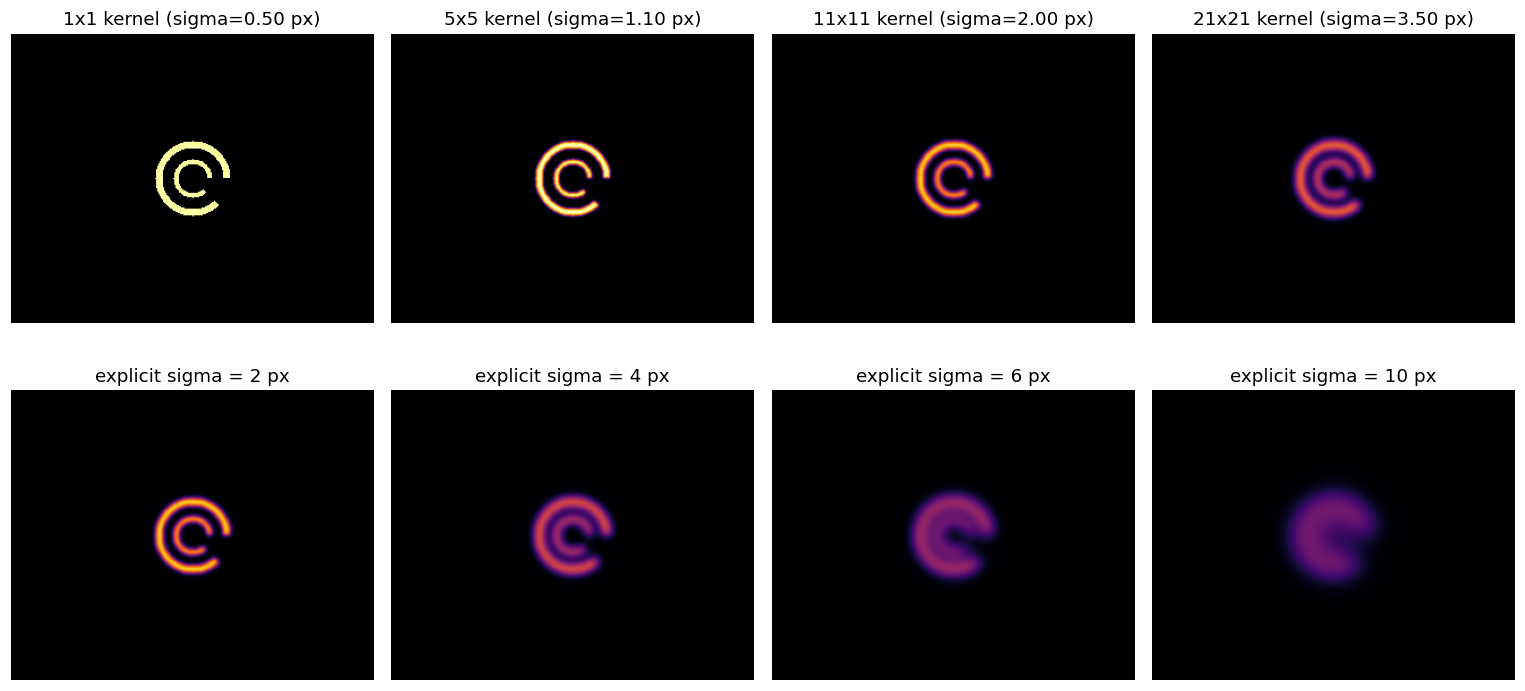

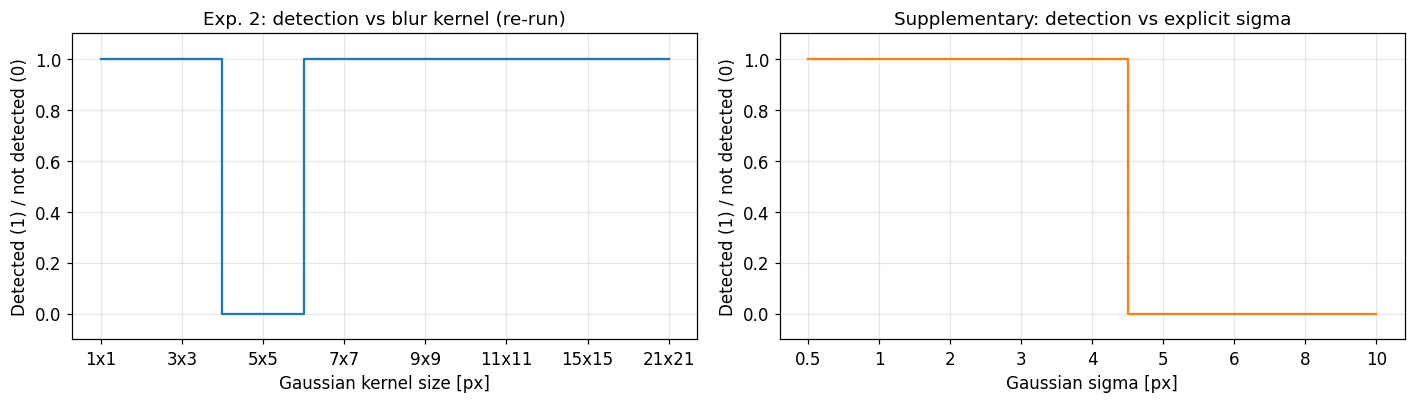

In [24]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, k in zip(ax[0], [1, 5, 11, 21]):
    b = cv2.GaussianBlur(base, (k, k), 0)
    a.imshow(b, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); a.set_title(f"{k}x{k} kernel (sigma={implied_sigma(k):.2f} px)"); a.axis("off")
for a, s in zip(ax[1], [2, 4, 6, 10]):
    b = cv2.GaussianBlur(base, (0, 0), sigmaX=s, sigmaY=s)
    a.imshow(b, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); a.set_title(f"explicit sigma = {s} px"); a.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].step(range(len(exp2)), [int(r['ok']) for r in exp2], where="mid")
ax[0].set_xticks(range(len(exp2))); ax[0].set_xticklabels([f"{r['k']}x{r['k']}" for r in exp2])
ax[0].set(xlabel="Gaussian kernel size [px]", ylabel="Detected (1) / not detected (0)", ylim=(-0.1, 1.1),
          title="Exp. 2: detection vs blur kernel (re-run)")
ax[1].step(range(len(exp2b)), [int(r['ok']) for r in exp2b], where="mid", color="C1")
ax[1].set_xticks(range(len(exp2b))); ax[1].set_xticklabels([str(r['sigma']) for r in exp2b])
ax[1].set(xlabel="Gaussian sigma [px]", ylabel="Detected (1) / not detected (0)", ylim=(-0.1, 1.1),
          title="Supplementary: detection vs explicit sigma")
plt.tight_layout(); plt.show()

In [25]:
# Supporting first-order estimate (1-D line model, NOT an optical MTF): peak of a Gaussian-blurred line of width w.
# Peak fraction of the original contrast = erf(w / (2*sqrt(2)*sigma)). The detector threshold sits at THRESHOLD/255 of the contrast.
from math import erf, sqrt
frac_thr = THRESHOLD / 255
print(f"binary threshold = {100*frac_thr:.1f}% of the target contrast")
print(f"{'sigma [px]':>10} {'peak, 4-px inner ring [%]':>26}")
for s in [1, 2, 3, 4, 5, 6, 8]:
    print(f"{s:10d} {100*erf(INNER_WIDTH/(2*sqrt(2)*s)):26.1f}")

binary threshold = 31.4% of the target contrast
sigma [px]  peak, 4-px inner ring [%]
         1                       95.4
         2                       68.3
         3                       49.5
         4                       38.3
         5                       31.1
         6                       26.1
         8                       19.7


**Figure 8.** *Top row:* blurred thermal images for four kernels (OpenCV-derived σ). *Second row:* explicit σ values. *Bottom plots:* detection outcome vs. kernel size (re-run) and vs. explicit σ (supplementary).

### Results
| Kernel | Implied σ [px] | **Re-run** | **Recorded** |
|---:|---:|---|---|
| 1×1 | 0.50 | detected | detected |
| 3×3 | 0.80 | detected | detected |
| **5×5** | **1.10** | **not detected** | detected |
| 7×7 | 1.40 | detected | detected |
| 9×9 | 1.70 | detected | detected |
| 11×11 | 2.00 | detected | detected |
| 15×15 | 2.60 | detected | detected |
| 21×21 | 3.50 | detected | detected |

Supplementary explicit-σ sweep: detected for σ ≤ 4 px, **not detected for σ ≥ 5 px** (tested: 0.5, 1, 2, 3, 4, 5, 6, 8, 10). A first-order line-blur estimate gives the 4 px ring a peak of ≈ 38 % of the contrast at σ = 4 and ≈ 31 % at σ = 5, against a threshold at 31.4 % of the contrast, consistent with the observed transition.

### Interpretation
Seven of the eight tested kernels are detected even though σ reaches 3.5 px (thinner than the 4 px inner ring, so the ring is substantially smeared). Hence the detector is largely **tolerant to blur**: thresholding re-creates a sharp binary contour from a smoothed profile, so blur is only fatal once the ring peak falls below the threshold (σ ≈ 5 px here, H2 supported). The isolated **failure at 5×5** (σ = 1.1 px) while larger kernels succeed is **non-monotonic**; it is another instance of the direction-estimate instability of Section 6.2, *not* a physical blur effect, and it contradicts the recorded "all detected".

### Limitation
This is **not an optical MTF or lens-resolution measurement**. A Gaussian is an approximation of a real PSF (real PSFs have different tails, may be anisotropic, and vary with the field of view); the detector's own tolerance largely sets the outcome. Blur is applied to a noiseless scene, so the real interaction of blur and noise is not addressed. The 5×5 discrepancy with the recorded result is unresolved.

## 11. Experiment 3 — Thermal noise

### Objective
Determine how much **simulated** Gaussian temperature noise the detector tolerates.

### Hypothesis
(H3) Detection stays ≈100 % while noise σ is small compared with the 4.7 °C background-to-threshold margin and then falls steeply as background pixels begin to cross the threshold in clusters that the 3 × 3 opening cannot remove.

### Controlled Variables
Distance 0.5 m, 15 °C contrast, no added blur, detector unchanged, 20 trials per level, seed 42.

### Independent Variable
Noise standard deviation σ ∈ {0, 0.5, 1, 1.5, 2, 3, 4, 5, 7, 10} °C (i.i.d. zero-mean Gaussian per pixel).

### Dependent Variable
Number of detections out of 20 (rate) with 95 % Wilson interval.

### Procedure
For each σ, 20 independent noisy images are generated from one `np.random.default_rng(42)` stream (consumed sequentially over all levels) and passed through preprocessing and detection. The original per-condition seeding is not documented; the recorded values were obtained with a possibly different random stream, so small differences are expected.

In [26]:
# Experiment 3 - simulated Gaussian temperature noise only (distance 0.5 m, 15 C contrast, no added blur).
NOISE_LEVELS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
RECORDED_EXP3 = {0.0: 20, 0.5: 20, 1.0: 20, 1.5: 20, 2.0: 20, 3.0: 20, 4.0: 15, 5.0: 2, 7.0: 1, 10.0: 0}

noise_rng = np.random.default_rng(RNG_SEED)       # one generator for the whole experiment; seed documented
exp3 = []
for s in NOISE_LEVELS:
    k = detection_count(lambda i: add_thermal_noise(base, s, noise_rng))
    lo, hi = wilson_ci(k, N_TRIALS)
    exp3.append(dict(s=s, k=k, lo=lo, hi=hi, rec=RECORDED_EXP3[s]))

print(f"{'sigma [C]':>9} {'re-run':>8} {'rate':>6} {'95% CI (Wilson)':>18} {'recorded':>9}")
for r in exp3:
    print(f"{r['s']:9.1f} {r['k']:>5}/20 {100*r['k']/20:5.0f}% {'[%3.0f%%, %3.0f%%]' % (100*r['lo'], 100*r['hi']):>18} {r['rec']:>6}/20")

sigma [C]   re-run   rate    95% CI (Wilson)  recorded
      0.0    20/20   100%       [ 84%, 100%]     20/20
      0.5    20/20   100%       [ 84%, 100%]     20/20
      1.0    20/20   100%       [ 84%, 100%]     20/20
      1.5    20/20   100%       [ 84%, 100%]     20/20
      2.0    20/20   100%       [ 84%, 100%]     20/20
      3.0    20/20   100%       [ 84%, 100%]     20/20
      4.0    16/20    80%       [ 58%,  92%]     15/20
      5.0     4/20    20%       [  8%,  42%]      2/20
      7.0     0/20     0%       [  0%,  16%]      1/20
     10.0     0/20     0%       [  0%,  16%]      0/20


In [27]:
# Supporting calculation (analytical, not a simulation): per-pixel threshold-crossing probabilities for Gaussian noise.
from math import erfc, sqrt
thr_C = BACKGROUND_TEMP + THRESHOLD / 255 * (TARGET_TEMP - BACKGROUND_TEMP)      # 29.71 C
up = thr_C - BACKGROUND_TEMP        # background pixel must rise by this much to be misread as 'hot'
down = TARGET_TEMP - thr_C          # target pixel must fall by this much to be misread as 'cold'
Q = lambda z: 0.5 * erfc(z / sqrt(2))
print(f"threshold = {thr_C:.2f} C  (background margin {up:.2f} C, target margin {down:.2f} C)")
print(f"{'sigma [C]':>9} {'P(background pixel > thr)':>26} {'P(target pixel < thr)':>22}")
for s in [1.0, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]:
    print(f"{s:9.1f} {100*Q(up/s):25.2f}% {100*Q(down/s):21.3f}%")

threshold = 29.71 C  (background margin 4.71 C, target margin 10.29 C)
sigma [C]  P(background pixel > thr)  P(target pixel < thr)
      1.0                      0.00%                 0.000%
      2.0                      0.93%                 0.000%
      3.0                      5.84%                 0.030%
      4.0                     11.97%                 0.503%
      5.0                     17.33%                 1.976%
      7.0                     25.07%                 7.070%
     10.0                     31.90%                15.164%


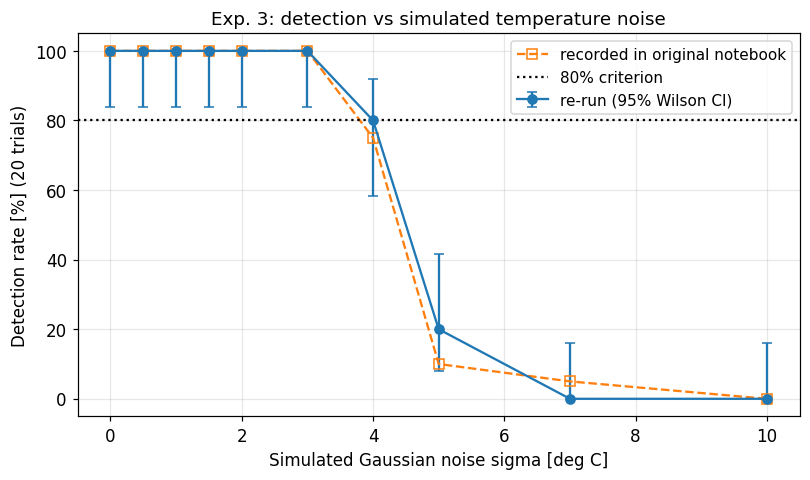

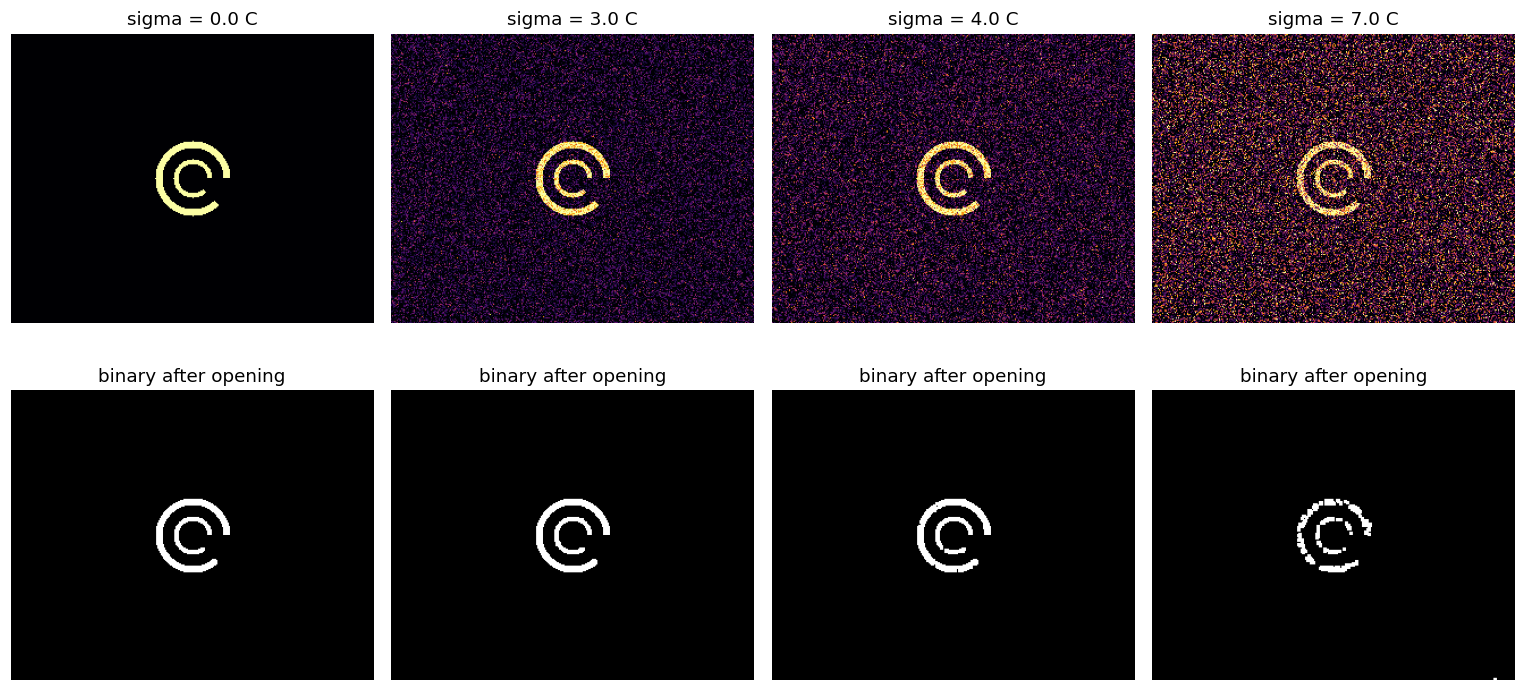

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
s_ = [r['s'] for r in exp3]
rate = np.array([r['k'] / N_TRIALS * 100 for r in exp3])
err = np.array([[100*(r['k']/N_TRIALS - r['lo']) for r in exp3], [100*(r['hi'] - r['k']/N_TRIALS) for r in exp3]])
ax.errorbar(s_, rate, yerr=err, fmt="o-", capsize=3, label="re-run (95% Wilson CI)")
ax.plot(s_, [100*r['rec']/N_TRIALS for r in exp3], "s--", mfc="none", label="recorded in original notebook")
ax.axhline(80, color="k", ls=":", label="80% criterion")
ax.set(xlabel="Simulated Gaussian noise sigma [deg C]", ylabel="Detection rate [%] (20 trials)",
       title="Exp. 3: detection vs simulated temperature noise", ylim=(-5, 105))
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
g = np.random.default_rng(RNG_SEED)
for j, s in enumerate([0.0, 3.0, 4.0, 7.0]):
    t = add_thermal_noise(base, s, g)
    ax[0, j].imshow(t, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP); ax[0, j].set_title(f"sigma = {s} C")
    ax[1, j].imshow(preprocess(t), cmap="gray"); ax[1, j].set_title("binary after opening")
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

**Figure 9.** *Top:* detection rate vs. simulated noise σ with 95 % Wilson intervals (re-run), the originally recorded result (dashed) and the 80 % criterion. *Bottom:* thermal images and binary images for σ = 0, 3, 4, 7 °C.

### Results
| σ [°C] | **Re-run** | **Recorded** |
|---:|---:|---:|
| 0 – 3 | 20/20 (100 %) | 20/20 (100 %) |
| 4 | 16/20 (80 %) | 15/20 (75 %) |
| 5 | 4/20 (20 %) | 2/20 (10 %) |
| 7 | 0/20 (0 %) | 1/20 (5 %) |
| 10 | 0/20 (0 %) | 0/20 (0 %) |

### Interpretation
Both runs show 100 % up to σ = 3 °C and a steep collapse between σ = 4 and 5 °C (H3 supported). The analytic table above explains the position: a background pixel must rise 4.71 °C to cross the threshold, which happens for ≈ 5.8 % of pixels at σ = 3 °C, ≈ 12 % at 4 °C and ≈ 17 % at 5 °C; once such false pixels are dense enough to survive the 3 × 3 opening and merge with or break the rings, the geometry is lost. The recorded and re-run values agree within sampling uncertainty (the 4 °C intervals overlap); the **80 % boundary lies between 3 and 4 °C (recorded) or between 4 and 5 °C (re-run)**, so the statement "≈ 3–4 °C, with large uncertainty from 20 trials" is the defensible one.

### Limitation
This is **simulated i.i.d. Gaussian noise, not the NETD of a real camera**; the σ at which detection fails must not be quoted as a camera sensitivity. Real thermal noise has spatial correlation, fixed-pattern non-uniformity, 1/f and drift components, and NETD is specified at a stated scene temperature and integration time. The threshold margin (4.71 °C) is tied to this particular 25–40 °C mapping, so the failure σ is a property of the detector configuration as well as of the noise.

## 12. Experiment 4 — Temperature contrast

### Objective
Determine how the target–background temperature difference ΔT affects detection.

### Hypothesis
(H4) With an adaptive threshold and no noise, detection persists to very small ΔT; with a fixed threshold it is lost when ΔT drops below the threshold margin (≈ 4.7 °C); with noise the minimum usable ΔT rises.

### Controlled Variables
Background 25 °C, distance 0.5 m, no blur, **no noise** (main experiment), detector geometry tests unchanged.

### Independent Variable
ΔT ∈ {15, 13, 11, 9, 7, 5, 4, 3, 2, 1} °C (target temperature 40 → 26 °C).

### Dependent Variable
Detection (20 identical deterministic trials). Supplementary: detections out of 20 under simulated noise σ ∈ {0.5, 1, 2} °C.

### Procedure
For each ΔT the 8-bit range is rescaled to [background, target] so the threshold stays at 80/255 of the *actual* contrast (**adaptive**, assumed to be what the original notes describe by "threshold adapted to the target/background pair"). A *fixed-range* variant — range stays 25–40 °C (threshold 29.7 °C) — is added to expose the effect of adaptation. The supplementary run adds noise to show how the idealised result degrades.

In [29]:
# Experiment 4 - temperature contrast only (background 25 C, noiseless, distance 0.5 m).
CONTRASTS = [15, 13, 11, 9, 7, 5, 4, 3, 2, 1]
RECORDED_EXP4 = {c: 20 for c in CONTRASTS}

exp4 = []
for c in CONTRASTS:
    tt = BACKGROUND_TEMP + c
    t = create_temperature_map(target_temp=tt)
    # (a) adaptive: 8-bit range is re-scaled to [background, target] for each contrast (what the original notes describe)
    ok_adapt = detect_concentric_pair(preprocess(t, min_temp=BACKGROUND_TEMP, max_temp=tt)) is not None
    # (b) fixed: 8-bit range stays 25-40 C and threshold 80/255 (= 29.7 C), i.e. the reference-scene setting
    ok_fixed = detect_concentric_pair(preprocess(t)) is not None
    exp4.append(dict(c=c, adapt=ok_adapt, fixed=ok_fixed))

print(f"fixed threshold = {BACKGROUND_TEMP + THRESHOLD/255*(TARGET_TEMP-BACKGROUND_TEMP):.1f} C")
print(f"{'dT [C]':>6} {'adaptive (re-run)':>18} {'fixed 25-40 C range':>20} {'recorded':>9}")
for r in exp4:
    print(f"{r['c']:6d} {'detected' if r['adapt'] else 'NOT detected':>18} {'detected' if r['fixed'] else 'NOT detected':>20} {'20/20':>9}")

# Supplementary (new): adaptive threshold WITH simulated noise, to show the noiseless result is not a camera limit.
CONTRAST_NOISE = [0.5, 1.0, 2.0]
SUP_CONTRASTS = [15, 10, 7, 5, 3, 2, 1]
sup_rng = np.random.default_rng(RNG_SEED)
exp4n = {}
for s in CONTRAST_NOISE:
    row = []
    for c in SUP_CONTRASTS:
        tt = BACKGROUND_TEMP + c
        t0 = create_temperature_map(target_temp=tt)
        k = detection_count(lambda i: add_thermal_noise(t0, s, sup_rng), min_temp=BACKGROUND_TEMP, max_temp=tt)
        row.append(k)
    exp4n[s] = row
print()
print("Supplementary: detections out of 20 (adaptive threshold) vs contrast, for simulated noise sigma")
print("dT [C]   " + " ".join(f"{c:>5}" for c in SUP_CONTRASTS))
for s, row in exp4n.items():
    print(f"sigma={s:<4}" + " ".join(f"{k:>5}" for k in row))

fixed threshold = 29.7 C
dT [C]  adaptive (re-run)  fixed 25-40 C range  recorded
    15           detected             detected     20/20
    13           detected             detected     20/20
    11           detected             detected     20/20
     9           detected             detected     20/20
     7           detected             detected     20/20
     5           detected             detected     20/20
     4           detected         NOT detected     20/20
     3           detected         NOT detected     20/20
     2           detected         NOT detected     20/20
     1           detected         NOT detected     20/20



Supplementary: detections out of 20 (adaptive threshold) vs contrast, for simulated noise sigma
dT [C]      15    10     7     5     3     2     1
sigma=0.5    20    20    20    20    20    14     0
sigma=1.0    20    20    19    17     5     0     0
sigma=2.0    19    19    12     0     0     0     0


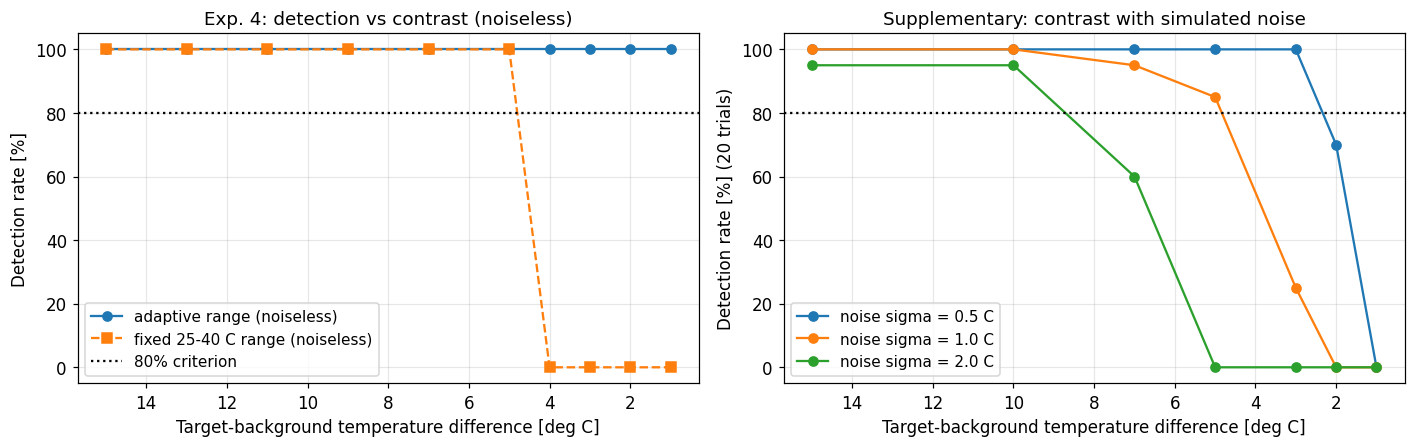

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = [r['c'] for r in exp4]
ax[0].plot(x, [100*int(r['adapt']) for r in exp4], "o-", label="adaptive range (noiseless)")
ax[0].plot(x, [100*int(r['fixed']) for r in exp4], "s--", label="fixed 25-40 C range (noiseless)")
ax[0].axhline(80, color="k", ls=":", label="80% criterion")
ax[0].invert_xaxis()
ax[0].set(xlabel="Target-background temperature difference [deg C]", ylabel="Detection rate [%]", ylim=(-5, 105),
          title="Exp. 4: detection vs contrast (noiseless)")
ax[0].legend()
for s, row in exp4n.items():
    ax[1].plot(SUP_CONTRASTS, [100*k/N_TRIALS for k in row], "o-", label=f"noise sigma = {s} C")
ax[1].axhline(80, color="k", ls=":"); ax[1].invert_xaxis()
ax[1].set(xlabel="Target-background temperature difference [deg C]", ylabel="Detection rate [%] (20 trials)", ylim=(-5, 105),
          title="Supplementary: contrast with simulated noise")
ax[1].legend(); plt.tight_layout(); plt.show()

**Figure 10.** *Left:* detection vs. ΔT for the adaptive and fixed 25–40 °C ranges (noiseless). *Right (supplementary):* detection vs. ΔT with simulated noise σ = 0.5, 1, 2 °C (20 trials each).

### Results
| ΔT [°C] | Adaptive (**re-run**) | Fixed 25–40 °C range (new) | **Recorded** |
|---:|---|---|---|
| 15 … 5 | detected | detected | 20/20 |
| 4, 3, 2, 1 | detected | **not detected** | 20/20 |

Supplementary (adaptive, noisy, detections / 20):

| σ \ ΔT [°C] | 15 | 10 | 7 | 5 | 3 | 2 | 1 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 0.5 °C | 20 | 20 | 20 | 20 | 20 | 14 | 0 |
| 1.0 °C | 20 | 20 | 19 | 17 | 5 | 0 | 0 |
| 2.0 °C | 19 | 19 | 12 | 0 | 0 | 0 | 0 |

### Interpretation
The recorded "100 % down to 1 °C" **is reproduced**, but only because (a) the scene is noiseless and (b) the threshold is rescaled to each ΔT, so a 1 °C step becomes as visible to the detector as a 15 °C step. With the fixed range the detector fails once ΔT < 4.7 °C (H4 first part supported: 5 °C detected, 4 °C not). With noise the usable ΔT rises quickly: at σ = 1 °C the 80 % boundary is ≈ 5 °C, at σ = 2 °C it exceeds 7 °C. The relevant physical quantity is therefore **ΔT relative to noise (signal-to-noise)**, not ΔT alone.

### Limitation
This does **not** establish the camera's minimum detectable temperature difference. A noiseless synthetic scene with perfect per-condition threshold adaptation is an upper bound on algorithmic capability; a real system would need to know the target temperature in advance to adapt. The supplementary noise levels are a coarse grid and use simulated Gaussian noise.

## 13. Experiment 5 — Spatial resolution (target size in pixels)

### Objective
Isolate the effect of the target's **pixel footprint** — the quantity that determines spatial sampling of the opening and ring separation — independent of distance interpolation, blur and noise.

### Hypothesis
(H5) A minimum footprint is required; detection falls from reliable to none over a narrow range; the result may not be smooth because of pixel rasterisation and hard detector thresholds.

### Controlled Variables
320 × 256 frame, 25 / 40 °C, 45° opening, radius ratio fixed at 2.0, ring-width : radius ratios fixed (0.2 outer, 0.133 inner), no blur, no noise, detector unchanged.

### Independent Variable
Outer ring radius $R_{out}\in\{30,27,24,21,18,16,14,12,10,9,8,7,6,5\}$ px (inner radius $R_{out}/2$; ring widths scaled proportionally). The Landolt-style resolving feature is the opening arc length $\alpha R$.

### Dependent Variable
Detection (success/failure) and the failing test from `diagnose`.

### Procedure
**New in this revision** — the original notebook contains no recorded target-size sweep, so there are no previous results to compare. Each size is drawn *directly* with `draw_c_mask` (analytic rasterisation, no interpolation), which is the difference from Experiment 1 (resizing with `INTER_AREA`). The notebook's Experiment 5B (below) varies the sensor instead.

In [31]:
# Experiment 5 - spatial resolution via target size (new run; the original notebook has no recorded target-size sweep).
# The same two-level C is rasterised directly at smaller radii in the 320x256 frame; ring widths scale proportionally.
# Fixed: 320x256 frame, 25/40 C, 45 deg gap, no blur, no noise, detector unchanged. Radius ratio fixed at 2.0.
OUTER_SWEEP = [30, 27, 24, 21, 18, 16, 14, 12, 10, 9, 8, 7, 6, 5]

def size_scene(R):
    k = R / OUTER_RADIUS
    t = np.full((HEIGHT, WIDTH), BACKGROUND_TEMP, dtype=np.float32)
    o = draw_c_mask(CX, CY, R, OUTER_WIDTH * k)
    i = draw_c_mask(CX, CY, R / 2, INNER_WIDTH * k)
    t[o | i] = TARGET_TEMP
    return t, OUTER_WIDTH * k, INNER_WIDTH * k

exp5 = []
for R in OUTER_SWEEP:
    t, wo, wi = size_scene(R)
    ok = detect_concentric_pair(preprocess(t)) is not None
    gap_px = np.radians(GAP_ANGLE) * R                      # arc length of the opening on the outer ring
    inner_gap_px = np.radians(GAP_ANGLE) * R / 2
    exp5.append(dict(R=R, wo=wo, wi=wi, gap=gap_px, igap=inner_gap_px, ok=ok))

print(f"{'R_out [px]':>10} {'w_out':>6} {'w_in':>6} {'outer gap arc [px]':>19} {'inner gap arc [px]':>19} {'result':>14}")
for r in exp5:
    print(f"{r['R']:10d} {r['wo']:6.2f} {r['wi']:6.2f} {r['gap']:19.1f} {r['igap']:19.1f} {'detected' if r['ok'] else 'NOT detected':>14}")

R_out [px]  w_out   w_in  outer gap arc [px]  inner gap arc [px]         result
        30   6.00   4.00                23.6                11.8       detected
        27   5.40   3.60                21.2                10.6   NOT detected
        24   4.80   3.20                18.8                 9.4   NOT detected
        21   4.20   2.80                16.5                 8.2   NOT detected
        18   3.60   2.40                14.1                 7.1   NOT detected
        16   3.20   2.13                12.6                 6.3   NOT detected
        14   2.80   1.87                11.0                 5.5   NOT detected
        12   2.40   1.60                 9.4                 4.7   NOT detected
        10   2.00   1.33                 7.9                 3.9   NOT detected
         9   1.80   1.20                 7.1                 3.5   NOT detected
         8   1.60   1.07                 6.3                 3.1   NOT detected
         7   1.40   0.93                

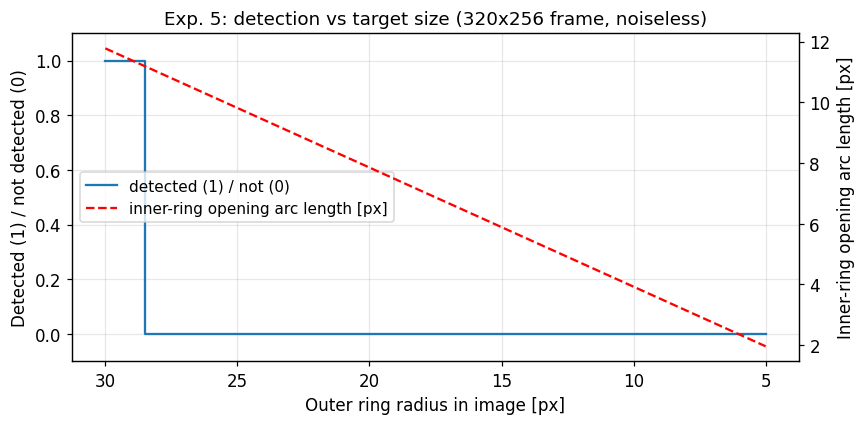

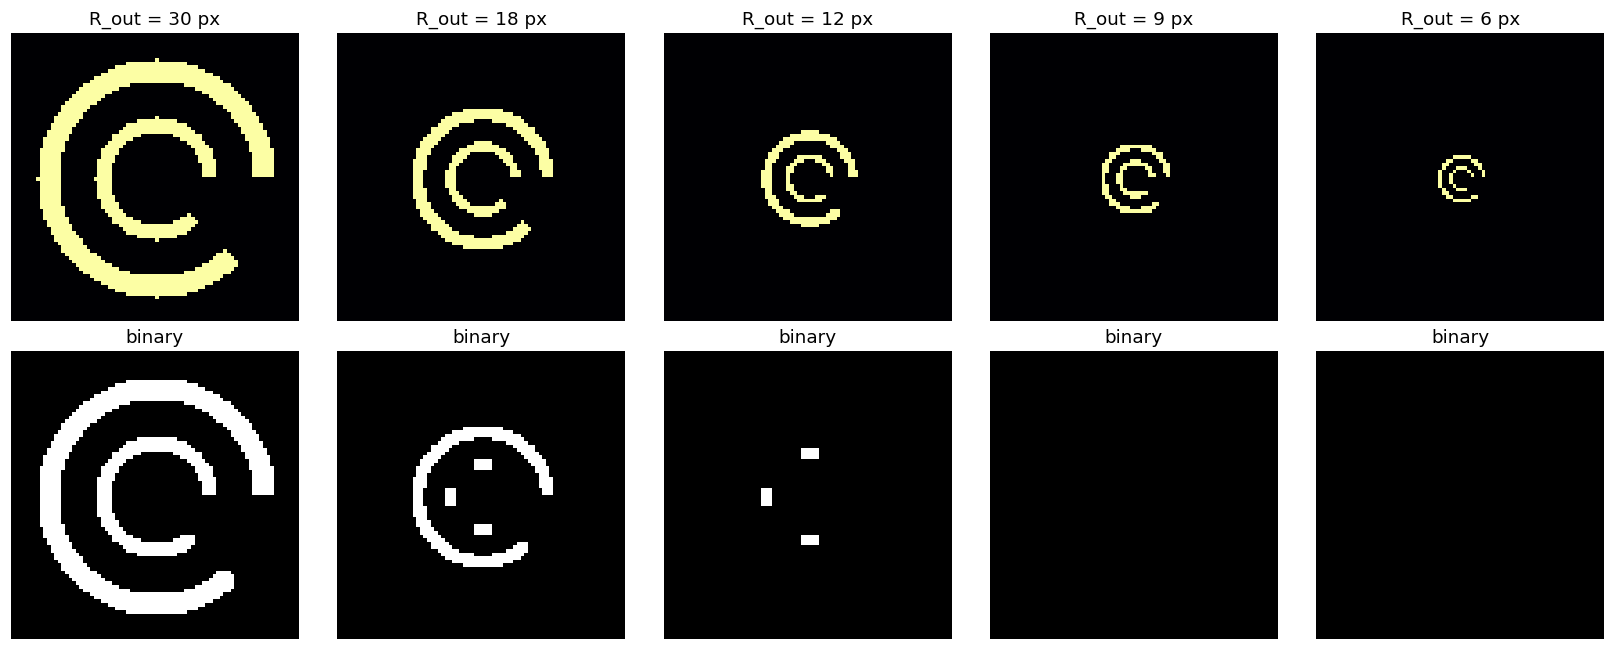

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
R_ = [r['R'] for r in exp5]
ax.step(R_, [int(r['ok']) for r in exp5], where="mid", label="detected (1) / not (0)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(R_, [r['igap'] for r in exp5], "r--", label="inner-ring opening arc length [px]")
ax2.set_ylabel("Inner-ring opening arc length [px]")
ax.invert_xaxis()
ax.set(xlabel="Outer ring radius in image [px]", ylabel="Detected (1) / not detected (0)", ylim=(-0.1, 1.1),
       title="Exp. 5: detection vs target size (320x256 frame, noiseless)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1+h2, l1+l2, loc="center left")
plt.tight_layout(); plt.show()

show = [30, 18, 12, 9, 6]
fig, ax = plt.subplots(2, len(show), figsize=(3*len(show), 6))
for j, R in enumerate(show):
    t, _, _ = size_scene(R)
    ax[0, j].imshow(t[CY-40:CY+40, CX-40:CX+40], cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    ax[0, j].set_title(f"R_out = {R} px")
    ax[1, j].imshow(preprocess(t)[CY-40:CY+40, CX-40:CX+40], cmap="gray"); ax[1, j].set_title("binary")
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

**Figure 11.** *Top:* detection outcome vs. outer radius (left axis) and the corresponding inner-ring opening arc length in pixels (right axis, red). *Bottom:* zoomed thermal and binary images for selected sizes.

In [33]:
print("Failure-mode diagnostic: Experiment 1 (distance)")
print(f"{'d [m]':>6} {'inner ring width [px]':>22}  first failing test")
for r in exp1:
    reason, info = diagnose(preprocess(simulate_distance(temperature, r['d'])))
    extra = "" if info is None else f"   (outer dir {info['outer_dir']:.0f}, inner dir {info['inner_dir']:.0f} deg)"
    print(f"{r['d']:6.1f} {r['inner_w']:22.2f}  {reason}{extra}")

print()
print("Failure-mode diagnostic: Experiment 5 (target size)")
print(f"{'R_out':>6} {'inner width':>12}  first failing test")
for r in exp5:
    t, _, _ = size_scene(r['R'])
    reason, info = diagnose(preprocess(t))
    extra = "" if info is None else f"   (outer dir {info['outer_dir']:.0f}, inner dir {info['inner_dir']:.0f} deg)"
    print(f"{r['R']:6d} {r['wi']:12.2f}  {reason}{extra}")

Failure-mode diagnostic: Experiment 1 (distance)
 d [m]  inner ring width [px]  first failing test
   0.5                   4.00  detected   (outer dir 206, inner dir 184 deg)
   0.6                   3.33  gap-direction mismatch (168 deg > 30 deg)   (outer dir 212, inner dir 20 deg)
   0.7                   2.86  gap-direction mismatch (163 deg > 30 deg)   (outer dir 218, inner dir 22 deg)
   0.8                   2.50  no pair passes centre/radius-ratio test
   0.9                   2.22  no pair passes centre/radius-ratio test
   1.0                   2.00  no pair passes centre/radius-ratio test
   1.5                   1.33  fewer than 2 contours
   2.0                   1.00  fewer than 2 contours
   3.0                   0.67  fewer than 2 contours
   4.0                   0.50  fewer than 2 contours

Failure-mode diagnostic: Experiment 5 (target size)
 R_out  inner width  first failing test
    30         4.00  detected   (outer dir 206, inner dir 184 deg)
    27         3.60  

### Results
| Outer radius | Inner ring width | Opening arc (outer / inner) | Result | First failing test |
|---:|---:|---|---|---|
| 30 px | 4.0 px | 23.6 / 11.8 px | **detected** | – |
| 27 px | 3.6 px | 21.2 / 10.6 px | not detected | gap-direction mismatch (≈179°) |
| 24 px | 3.2 px | 18.8 / 9.4 px | not detected | gap-direction mismatch (≈175°) |
| 21 – 12 px | 2.8 – 1.6 px | 16.5 – 9.4 / 8.2 – 4.7 px | not detected | no pair passes centre/radius test |
| 10 – 5 px | 1.3 – 0.7 px | ≤ 7.9 / ≤ 3.9 px | not detected | fewer than 2 contours |

### Interpretation
Only the largest size (the original reference target) is detected; a **10 % reduction in radius already causes failure**, which indicates that the baseline success lies at the edge of what this detector tolerates (a brittle threshold, not a graceful acuity curve). The failure mechanism at 27 and 24 px is again the direction test (outer estimate ≈ 202°, inner ≈ 22–26° — the inner ring's scan now finds the *true* opening while the outer ring's scan stays centroid-dominated). Below ≈ 2.8 px inner ring width, the 3 × 3 opening removes the inner ring. This sweep is **monotonic as a step function**, but the same detector **succeeds at 160 × 128 in Experiment 5B** where the outer radius is 25 px and ring widths 4 / 3 px — i.e. a target of *smaller or equal* pixel size than the failing 27 and 24 px cases here. Pixel footprint alone therefore does **not** predict detection: the rasterisation path (hard-edged analytic mask here vs. area-averaged downsampling in 5B) changes edge pixel values, centroids, and the direction estimates. This non-monotonic dependence on rasterisation is reported rather than smoothed over.

### Limitation
The detector, not the optics, defines the transition; the numbers are specific to this detector, this 45° opening, and these ring-width ratios. Because all trials are identical, the conclusion rests on a single deterministic observation per size. A finer size grid, sub-pixel target offsets (random sub-pixel shifts to probe rasterisation variance) and an improved centre estimator are needed before an acuity threshold can be claimed. The study cannot yet be converted to "pixels per gap" criteria for a physical camera.

## 14. Experiment 5B — Camera resolution (simulation)

### Objective
Test how sensor resolution (pixel count at a fixed scene and field of view) affects detection.

### Hypothesis
(H6) Reducing resolution reduces pixels on target and eventually prevents detection; absolute-pixel detector tolerances (the 5 px centre tolerance) may add resolution-dependent effects.

### Controlled Variables
One fixed **master target** at 640 × 512 px (outer radius 100 px/width 16 px, inner radius 50 px/width 12 px, 25 / 40 °C, same 45° opening), no blur, no noise, detector unchanged.

### Independent Variable
Simulated sensor resolution: 640 × 512, 320 × 256, 160 × 128, 80 × 64 (created by `cv2.resize(..., INTER_AREA)` of the master temperature field).

### Dependent Variable
Detection over 20 deterministic trials; contour count, centre offset and radius ratio (new diagnostics).

### Procedure
**What was simulated:** an *ideal area-averaging detector array* observing the same scene at four pixel pitches (each simulated pixel is the mean temperature over the master pixels it covers). It does not model detector fill factor, optics, crosstalk, fixed-pattern noise or ADC quantisation. Note that, at fixed field of view, a lower resolution also makes the target *smaller in pixels*: outer radius 100 → 50 → 25 → 12.5 px.

The **original code cell is kept unchanged**; its printed output is the authoritative original result.

In [34]:
MASTER_WIDTH, MASTER_HEIGHT = 640, 512

RESOLUTIONS = [
    (640, 512),
    (320, 256),
    (160, 128),
    (80, 64)
]


def create_master_target():
    temp = np.full(
        (MASTER_HEIGHT, MASTER_WIDTH),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    cx = MASTER_WIDTH // 2
    cy = MASTER_HEIGHT // 2

    outer = draw_c_mask(
        cx, cy, 100, 16,
        height=MASTER_HEIGHT,
        width_img=MASTER_WIDTH
    )

    inner = draw_c_mask(
        cx, cy, 50, 12,
        height=MASTER_HEIGHT,
        width_img=MASTER_WIDTH
    )

    temp[outer | inner] = TARGET_TEMP
    return temp


master_temperature = create_master_target()

resolution_results = []

for width, height in RESOLUTIONS:
    camera_temperature = cv2.resize(
        master_temperature,
        (width, height),
        interpolation=cv2.INTER_AREA
    )

    detected = 0

    for _ in range(20):
        result, _ = run_detector(camera_temperature)
        if result is not None:
            detected += 1

    rate = detected / 20 * 100

    resolution_results.append(
        (width, height, detected, rate)
    )

    print(
        f"{width} × {height} → "
        f"{detected}/20 ({rate:.1f}%)"
    )

640 × 512 → 0/20 (0.0%)


320 × 256 → 20/20 (100.0%)


160 × 128 → 20/20 (100.0%)
80 × 64 → 0/20 (0.0%)


In [35]:
# Exp. 5B diagnostics (new, read-only: the detector is NOT changed for the reported result above).
print(f"{'resolution':>12} {'candidates':>11} {'center offset [px]':>19} {'tolerance [px]':>15} {'radius ratio':>13}")
diag5b = []
for w, h, k_, rate_ in resolution_results:
    cam = cv2.resize(master_temperature, (w, h), interpolation=cv2.INTER_AREA)
    cands = sorted(find_contour_candidates(preprocess(cam)), key=lambda c: -c['radius'])
    if len(cands) >= 2:
        off = float(np.linalg.norm(cands[0]['center'] - cands[1]['center']))
        ratio = cands[0]['radius'] / max(cands[1]['radius'], 1e-9)
        print(f"{w:>5}x{h:<6} {len(cands):>11} {off:19.2f} {CENTER_TOLERANCE:15.1f} {ratio:13.2f}")
    else:
        off, ratio = float('nan'), float('nan')
        print(f"{w:>5}x{h:<6} {len(cands):>11} {'n/a':>19} {CENTER_TOLERANCE:15.1f} {'n/a':>13}")
    diag5b.append((w, h, k_, off))

# What-if: scale the centre tolerance with image width (5 px at 320 px wide). Diagnostic only.
saved_tol = CENTER_TOLERANCE
print()
print("What-if (diagnostic only): CENTER_TOLERANCE scaled with sensor width")
whatif = []
for w, h, _, _ in resolution_results:
    CENTER_TOLERANCE = saved_tol * w / 320
    cam = cv2.resize(master_temperature, (w, h), interpolation=cv2.INTER_AREA)
    ok = detect_concentric_pair(preprocess(cam)) is not None
    whatif.append((w, h, ok))
    print(f"{w:>5}x{h:<4} tolerance = {CENTER_TOLERANCE:5.1f} px -> {'detected' if ok else 'NOT detected'}")
CENTER_TOLERANCE = saved_tol

  resolution  candidates  center offset [px]  tolerance [px]  radius ratio
  640x512              2                6.96             5.0          1.93
  320x256              2                3.42             5.0          1.93
  160x128              2                1.29             5.0          1.92
   80x64               3               18.03             5.0          1.24

What-if (diagnostic only): CENTER_TOLERANCE scaled with sensor width
  640x512  tolerance =  10.0 px -> detected
  320x256  tolerance =   5.0 px -> detected
  160x128  tolerance =   2.5 px -> detected
   80x64   tolerance =   1.2 px -> NOT detected


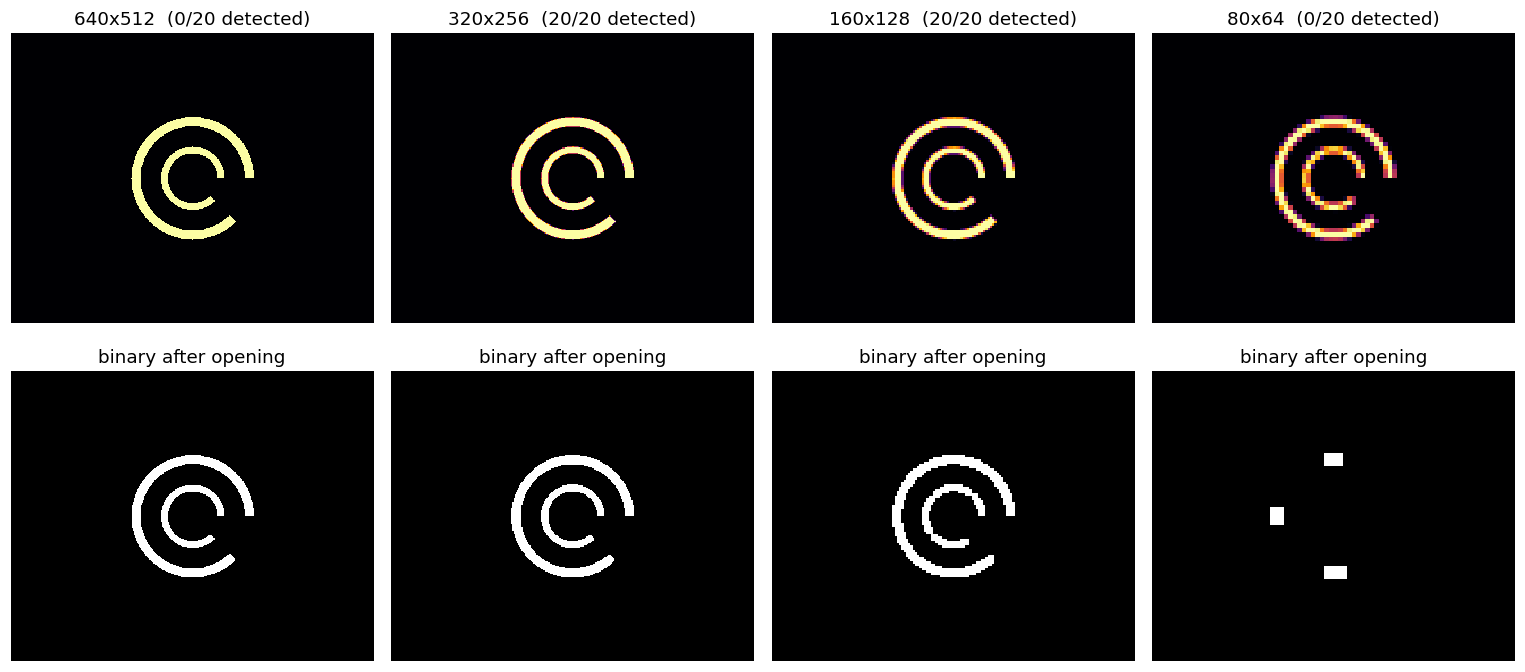

In [36]:
fig, ax = plt.subplots(2, 4, figsize=(14, 6.5))
for j, (w, h, k_, rate_) in enumerate(resolution_results):
    cam = cv2.resize(master_temperature, (w, h), interpolation=cv2.INTER_AREA)
    ax[0, j].imshow(cam, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP, interpolation="nearest")
    ax[0, j].set_title(f"{w}x{h}  ({k_}/20 detected)")
    ax[1, j].imshow(preprocess(cam), cmap="gray", interpolation="nearest"); ax[1, j].set_title("binary after opening")
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

**Figure 12.** The same target imaged at four simulated resolutions (top: thermal image, nearest-neighbour display; bottom: binary image after opening) with the detection result for each.

### Results
| Resolution | Outer R [px] | **Detection (code output, re-run)** | Original markdown | Centre offset (tolerance 5 px) | Note |
|---|---:|---|---|---:|---|
| 640 × 512 | 100 | **0/20** | 20/20 | 6.96 px | centre-distance test rejects (> 5 px) |
| 320 × 256 | 50 | 20/20 | 20/20 | 3.42 px | – |
| 160 × 128 | 25 | 20/20 | 20/20 | 1.29 px | – |
| 80 × 64 | 12.5 | 0/20 | 0/20 | 18.0 px | 3 contours; radius ratio 1.24 < 1.3 |

Diagnostic what-if (**not** the reported result): scaling `CENTER_TOLERANCE` in proportion to sensor width (10 / 5 / 2.5 / 1.2 px) gives detected, detected, detected, not detected.

### Interpretation
The original notebook contained a **conflict**: the markdown stated 100 % at 640 × 512, while the executed code printed **0/20**. This revision re-executes the code and obtains 0/20, so the printed output is taken as correct. The failure at the *highest* resolution is not a loss of information: the same absolute 5 px centre tolerance is too strict for a target four times bigger, because the centroid offset of a C scales with its radius (≈ 0.07 R). Detection is therefore **non-monotonic in resolution** (0/20, 20/20, 20/20, 0/20) for a reason that is an artefact of the detector, not of imaging. At 80 × 64 the target is ≈ 12 px in outer radius with a ≈ 1 px ring; the rings fragment (three contours) and detection fails for a genuine loss of resolution. Within the tested set the *lowest successful simulated resolution* is 160 × 128 for this target and detector (H6 partly supported).

### Limitation
This is a simulation result, not physical camera performance. 160 × 128 is **not** a universal minimum resolution: it depends on this target's size in the frame, the 45° opening, the detector's tolerances, the ideal area-averaging model, and a four-point resolution grid. A physical camera has its own field of view, optics, fill factor and noise, so the target would span a different number of pixels. The 640 × 512 failure shows the detector needs scale-aware tolerances (or a better centre estimator) before resolution comparisons are meaningful.

## 15. Combined camera simulation

### Objective
Evaluate the full simulated imaging chain with several degradations acting together.

### Pipeline
```text
distance  →  target scaling (0.5/d)  →  distance-dependent Gaussian blur σ(d)  →  simulated Gaussian noise σ_n  →  preprocessing  →  detection
```
This is a **computational model of a thermal imaging system, not a calibrated physical camera model**: the blur law (σ = 0.5 + 0.8 (d − 0.5) px) and the noise levels are assumed parameters.

### Controlled / independent / dependent
Controlled: 15 °C contrast, 320 × 256 frame, seed 42, 20 trials per cell, detector unchanged. Independent: distance ∈ {0.5, 0.6, 0.7, 0.8, 1.0} m and noise σ_n ∈ {0, 1, 2, 3} °C. Dependent: detections out of 20.

### Procedure
The original notebook describes a combined experiment (distance, noise, contrast) but its code was not retained, so this grid is a **re-implementation from the documented building blocks** (blur included, as the model above defines).

In [37]:
# Combined camera simulation: distance + target scaling + blur + simulated noise -> detection.
# Re-implemented here from the existing building blocks; blur follows the distance-dependent sigma model of cell "distance and blur".
def combined_pipeline(distance, noise_sigma, contrast, generator):
    target_temp = BACKGROUND_TEMP + contrast
    t = create_temperature_map(target_temp=target_temp)
    t = simulate_distance(t, distance)                     # distance + target scaling
    t = simulate_blur(t, distance)                         # Gaussian blur, sigma = f(distance)
    t = add_thermal_noise(t, noise_sigma, generator)       # simulated measurement noise
    img = preprocess(t, min_temp=BACKGROUND_TEMP, max_temp=target_temp)
    return detect_concentric_pair(img) is not None

COMB_DISTANCES = [0.5, 0.6, 0.7, 0.8, 1.0]
COMB_NOISE = [0.0, 1.0, 2.0, 3.0]
comb_rng = np.random.default_rng(RNG_SEED)
comb = np.zeros((len(COMB_DISTANCES), len(COMB_NOISE)), dtype=int)
for i, d in enumerate(COMB_DISTANCES):
    for j, s in enumerate(COMB_NOISE):
        comb[i, j] = sum(combined_pipeline(d, s, 15.0, comb_rng) for _ in range(N_TRIALS))

print("Detections out of 20 (contrast 15 C, blur ON)")
print("d [m] \\ sigma [C]  " + " ".join(f"{s:>5}" for s in COMB_NOISE))
for d, row in zip(COMB_DISTANCES, comb):
    print(f"{d:>16}  " + " ".join(f"{k:>5}" for k in row))

Detections out of 20 (contrast 15 C, blur ON)
d [m] \ sigma [C]    0.0   1.0   2.0   3.0
             0.5     20    20    18    15
             0.6      0     6     9     8
             0.7      0     0     1     4
             0.8      0     0     1     0
             1.0      0     1     0     0


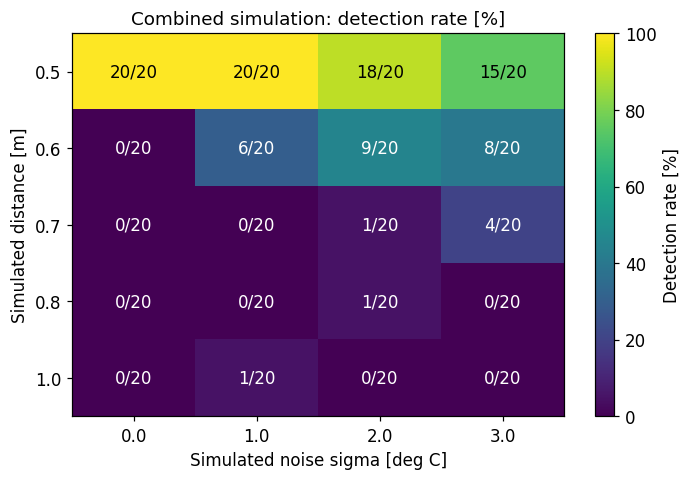

In [38]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(comb / N_TRIALS * 100, cmap="viridis", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(COMB_NOISE))); ax.set_xticklabels(COMB_NOISE)
ax.set_yticks(range(len(COMB_DISTANCES))); ax.set_yticklabels(COMB_DISTANCES)
for i in range(comb.shape[0]):
    for j in range(comb.shape[1]):
        ax.text(j, i, f"{comb[i,j]}/20", ha="center", va="center", color="w" if comb[i,j] < 12 else "k")
ax.set(xlabel="Simulated noise sigma [deg C]", ylabel="Simulated distance [m]", title="Combined simulation: detection rate [%]")
ax.grid(False); plt.colorbar(im, label="Detection rate [%]"); plt.tight_layout(); plt.show()

**Figure 13.** Detection rate (colour and counts) for the combined simulation, as a function of simulated distance and simulated noise.

### Results and interpretation
At 0.5 m detection falls with noise (20/20 → 15/20 at 3 °C). At 0.6 m detection is 0 % without noise but **non-zero with noise** (6/20, 9/20, 8/20); at 0.7 m it is 0/20 at σ = 0 and 1 °C, then 1/20 and 4/20 at σ = 2 and 3 °C. This reproduces *qualitatively* the originally recorded observation that, at 0.7 m with 15 °C contrast, adding noise changed the outcome from 0 % to a non-zero rate (recorded value 65 %; **that value is not reproduced** here, and the recorded run did not include the same blur model).

This does **not** mean noise physically improves visibility. Random pixel changes perturb the contour centroids and angular-gap estimates and can accidentally bring the two direction estimates into agreement (Section 6.2). It is a **detector-behaviour diagnostic**, so the combined grid must not be read as a physical performance threshold.

### Limitation
Assumed blur law, simulated noise, ideal thermal field, one contrast, five distances, coarse noise grid; small cell counts (20 trials); outcomes strongly influenced by the detector's fragility.

## 16. Results summary

All values come from this notebook (original recorded text and the re-execution above). *Rec.* = originally recorded; *Re-run* = executed in this notebook.

| Experiment | Independent variable | Controlled variables | Trials | Main result | Scientific interpretation | Major limitation |
|---|---|---|---|---|---|---|
| **1 Distance** | Simulated distance 0.5 – 4 m (scale 0.5/d) | 15 °C, 320×256, no blur, no noise | 20 (deterministic) | Rec.: 100 % to 0.7 m, 0 % from 0.8 m. Re-run: detected **only at 0.5 m**; fails 0.6–0.7 m (direction test), 0.8–1.0 m (inner ring lost), ≥ 1.5 m (< 2 contours) | Pixel occupancy falls as 1/d; three distinct failure mechanisms; recorded 0.6–0.7 m success not reproduced | Image-space scale, not camera range; detector-defined threshold; unresolved discrepancy |
| **2 Blur** | Gaussian kernel 1–21 px (σ 0.5–3.5) + explicit σ 0.5–10 px | 0.5 m, 15 °C, no noise | 1 deterministic evaluation | Rec.: all kernels detected. Re-run: 7/8 (5×5 fails); σ ≤ 4 px detected, σ ≥ 5 px not | Thresholding makes the detector blur-tolerant; fails when ring peak < threshold (≈ 31 %) | Not an MTF / lens-resolution measurement; Gaussian ≠ real PSF |
| **3 Noise** | Gaussian σ 0 – 10 °C | 0.5 m, 15 °C, no blur, seed 42 | 20 per level | Rec.: 100 % to 3 °C, 75 % at 4 °C, 10 % at 5 °C. Re-run: 100 % to 3 °C, 80 % at 4 °C, 20 % at 5 °C | Failure follows background pixels crossing the 4.7 °C margin; 80 % boundary ≈ 3–5 °C | Not NETD; i.i.d. Gaussian only; 20 trials give wide CIs |
| **4 Contrast** | ΔT 15 → 1 °C | 25 °C background, 0.5 m, no blur, **no noise** | 20 (deterministic) | Rec. and re-run: 100 % at all ΔT with adaptive threshold; fixed range fails for ΔT < 4.7 °C; with σ = 1 °C the 80 % boundary ≈ 5 °C | Ideal-condition result reflects threshold adaptation; SNR, not ΔT alone, matters | Does not give a camera's minimum detectable ΔT |
| **5 Spatial res. (target size)** | Outer radius 30 → 5 px | 320×256, 15 °C, no blur / noise | 20 (deterministic) | Only R = 30 px detected; R = 27, 24 direction mismatch; R ≤ 21 inner ring lost | Brittle, detector-limited transition; footprint alone does not predict detection (5B succeeds at R = 25) | New run (no recorded values); rasterisation-dependent; single observation per size |
| **5B Camera resolution** | 640×512 → 80×64 | Same master target, no blur / noise | 20 (deterministic) | 0/20, 20/20, 20/20, 0/20 (code output; original markdown said 100 % at 640×512) | 640×512 fails because absolute 5 px centre tolerance is too strict; 80×64 fails by loss of structure | Simulation only; 160×128 is not a universal minimum |
| **Combined** | Distance × noise (blur on) | 15 °C, seed 42 | 20 per cell | 0.5 m: 20 → 15 /20 with noise; 0.6–0.7 m: 0/20 without noise; with noise up to 9/20 (0.6 m) and 4/20 (0.7 m) | Noise can accidentally align the direction estimates; detector-behaviour diagnostic | Assumed blur law; not a physical threshold; recorded 65 % not reproduced |

**Figures.** All figures in this notebook have titles, labelled axes (with units), legends where several series appear, and a caption directly below (Figures 1–13). Where an experiment has both a representative image panel and a quantitative plot, both are provided.

## 17. Reproducibility

The cell below prints the software versions and every parameter used. The notebook is deterministic given these settings: noise experiments use `np.random.default_rng(42)` (one stream per experiment, consumed in order); all other experiments contain no randomness. Running order matters for experiments that share a generator.

| Item | Value |
|---|---|
| Random seed | 42 (`RNG_SEED`) |
| Trials | 20 per condition (`N_TRIALS`), reliability criterion ≥ 80 % |
| Image sizes | 320 × 256 px (reference); 640 × 512 master for Exp. 5B |
| Temperatures | background 25 °C, target 40 °C (ΔT = 15 °C unless varied) |
| Detector thresholds | binary threshold 80/255 (≈ 29.7 °C); opening kernel 3 × 3 px; contour area > 2 px²; centre tolerance 5.0 px; radius ratio ≥ 1.30; min gap 20°; direction tolerance 30° |
| Geometry | outer radius/width 30/6 px, inner 15/4 px, gap 45°, centre (160, 128) |
| Simulation | reference distance 0.5 m; blur σ = 0.5 + 0.8 (d − 0.5) px (min 0.1); Gaussian noise N(0, σ²) in °C |

**Software.** The original outputs were produced with NumPy 2.1.3, OpenCV 5.0.0 and Matplotlib 3.10.0. Rerunning with a different OpenCV major version could in principle change contour or morphology details; whether this explains the Exp. 1 discrepancy **has not been tested**.

In [39]:
import platform, sys
print("Python      :", sys.version.split()[0], "|", platform.platform())
print("NumPy       :", np.__version__, "| OpenCV:", cv2.__version__, "| Matplotlib:", plt.matplotlib.__version__)
print("Original notebook outputs were produced with NumPy 2.1.3 / OpenCV 5.0.0 / Matplotlib 3.10.0")
print()
params = {
    "RNG_SEED": RNG_SEED, "N_TRIALS": N_TRIALS, "RELIABILITY": RELIABILITY,
    "frame [px]": (WIDTH, HEIGHT), "master frame [px]": (MASTER_WIDTH, MASTER_HEIGHT),
    "background / target [C]": (BACKGROUND_TEMP, TARGET_TEMP),
    "outer R / width [px]": (OUTER_RADIUS, OUTER_WIDTH), "inner R / width [px]": (INNER_RADIUS, INNER_WIDTH),
    "gap angle [deg]": GAP_ANGLE, "REFERENCE_DISTANCE [m]": REFERENCE_DISTANCE,
    "BASE_BLUR_SIGMA / BLUR_PER_METER": (BASE_BLUR_SIGMA, BLUR_PER_METER),
    "THRESHOLD (0-255) / equivalent [C]": (THRESHOLD, round(BACKGROUND_TEMP + THRESHOLD/255*(TARGET_TEMP-BACKGROUND_TEMP), 2)),
    "opening KERNEL_SIZE [px]": KERNEL_SIZE,
    "CENTER_TOLERANCE [px]": CENTER_TOLERANCE, "RADIUS_RATIO_MIN": RADIUS_RATIO_MIN,
    "MIN_GAP_ANGLE [deg]": MIN_GAP_ANGLE, "GAP_DIRECTION_TOLERANCE [deg]": GAP_DIRECTION_TOLERANCE,
    "contour area filter [px^2]": "> 2", "gap scan": "360 angles, radius +/-2 px, 7 samples",
    "distance sweep [m]": DIST_SWEEP, "blur kernels [px]": BLUR_KERNELS, "noise sigma [C]": NOISE_LEVELS,
    "contrasts [C]": CONTRASTS, "target sizes R_out [px]": OUTER_SWEEP, "camera resolutions": RESOLUTIONS,
}
for k, v in params.items():
    print(f"{k:38s}: {v}")

Python      : 3.12.3 | Linux-6.18.44-fc-v80-x86_64-with-glibc2.39
NumPy       : 2.4.4 | OpenCV: 4.13.0 | Matplotlib: 3.10.8
Original notebook outputs were produced with NumPy 2.1.3 / OpenCV 5.0.0 / Matplotlib 3.10.0

RNG_SEED                              : 42
N_TRIALS                              : 20
RELIABILITY                           : 0.8
frame [px]                            : (320, 256)
master frame [px]                     : (640, 512)
background / target [C]               : (25.0, 40.0)
outer R / width [px]                  : (30.0, 6.0)
inner R / width [px]                  : (15.0, 4.0)
gap angle [deg]                       : 45.0
REFERENCE_DISTANCE [m]                : 0.5
BASE_BLUR_SIGMA / BLUR_PER_METER      : (0.5, 0.8)
THRESHOLD (0-255) / equivalent [C]    : (80, 29.71)
opening KERNEL_SIZE [px]              : 3
CENTER_TOLERANCE [px]                 : 5.0
RADIUS_RATIO_MIN                      : 1.3
MIN_GAP_ANGLE [deg]                   : 20.0
GAP_DIRECTION_TOLERANCE [de

## 18. Limitations

1. **Simulation only.** No physical thermal-camera measurement is contained in this notebook; every result is a simulation result.
2. **Gaussian blur is an approximation.** It is not a calibrated optical PSF/MTF; Experiment 2 is not an MTF or lens-resolution measurement.
3. **Gaussian temperature noise is not real thermal-camera noise.** It does not represent NETD, fixed-pattern noise, spatial correlation or drift; no NETD value should be inferred.
4. **Distance scaling is a simplified image-space model.** It has no IFOV, optics, atmospheric transmission or perspective effects.
5. **The synthetic temperature field is idealised.** Emissivity, conduction, convection, thermal inertia, reflected radiation and camera calibration are not modelled; the target is a perfectly uniform 40 °C on a uniform 25 °C background.
6. **Detector dependence.** Results depend on the threshold, 3 × 3 morphology and geometric tolerances. The centroid-based centre estimate is biased for a C (Section 6.2) and the centre tolerance is in absolute pixels (Exp. 5B), so some failures and successes reflect the detector, not imaging resolution.
7. **Deterministic experiments have one effective observation.** "20/20" in Experiments 1, 2, 4, 5 and 5B is a single result repeated.
8. **Recorded vs. re-run discrepancies are unresolved** (Exp. 1, Exp. 2 at 5×5, Exp. 5B markdown, combined 65 %). The original code for Experiments 1–4 and the combined experiment was not available in the notebook.
9. **Small trial counts.** 20 trials give wide confidence intervals; the 80 % criterion is a project convention.
10. **Single target size, opening and contrast per experiment**, no sub-pixel shifts, rotations or multiple opening orientations.
11. **Simulation results must be validated with a real thermal camera and a physical target** (Section 19).

## 19. Physical validation plan

No hardware specification is assumed here; fields in angle brackets must be filled from the actual equipment.

| Item | What to record / do |
|---|---|
| Camera model / specification | `<model>`, resolution, IFOV or lens FOV, spectral band, frame rate, stated NETD and its conditions, radiometric output availability |
| Target material | `<material>` (e.g. 3D-printed material plus heating layer); thickness; emissivity of surface (measured or from datasheet); surface finish |
| Target temperature | Heating method; measured with contact probe / reference; stability (± °C) during the test |
| Background temperature | Material/backdrop; measured temperature; uniformity |
| Distance | Series of measured distances (laser rangefinder); target size in pixels recorded at each |
| Camera-to-target alignment | Fixed mount; target normal to the optical axis; record tilt; repeat with several in-plane rotations of the opening |
| Ambient conditions | Air temperature, humidity, airflow, nearby heat sources, reflections |
| Number of repeated trials | ≥ 20 independent frames per condition, re-aligned between repeats where possible |
| Raw thermal frame recording | Save raw radiometric frames (not only colour-mapped video) with metadata |
| Calibration | Non-uniformity correction state; blackbody or reference-target check; warm-up time |
| Detection criterion | Same geometric detector, plus a *human-observer* gap-orientation judgement as an independent reference |
| Statistical reporting | Detection rate with 95 % intervals, ΔT and distance at 80 % reliability, number of frames and conditions, full raw data release |

**Detector fixes to make before the physical test** (found in this study): estimate each ring's centre by fitting a circle/ellipse to its pixels rather than using the C centroid; make centre tolerance proportional to ring radius; measure the opening against the *fitted* centre and compare against ground truth orientation; add random sub-pixel shifts and several opening orientations to the simulation.

## 20. Research contribution

This work contributes, within the limits stated above:

1. **A structured two-level concentric-C thermal target** with an exactly known geometry, designed so the opening must be resolved and the two levels must agree in centre and direction.
2. **A physics-informed computational thermal-image model** (geometry → temperature → distance → blur → noise → 8-bit image) whose parameters are explicit and adjustable.
3. **A classical, geometry-based detection pipeline** (threshold, morphology, contours, centroid/radius tests, angular-gap analysis) with negative controls and a failure-mode diagnostic.
4. **A controlled investigation of distance, blur, noise, contrast and resolution**, with each variable isolated and each result reported against its stated limitation.
5. **A reproducible methodology** for evaluating thermal spatial resolving capability, including an honest account of where re-execution did not reproduce earlier numbers.
6. **A diagnosed detector weakness** (centroid-biased gap direction, absolute-pixel tolerance) that must be fixed before physical measurements.
7. **A foundation for later physical validation** on the RoboCup Rescue thermal camera.

No claim of novelty over existing Landolt-C or thermal-acuity methods is made; no literature comparison is contained in this notebook.

## 21. Conclusion

**What was demonstrated computationally.**
- A two-level concentric-C thermal target can be detected by a classical geometry-based pipeline under ideal simulated conditions, and the pipeline rejects two complete concentric circles and the other tested controls.
- In the **re-executed** simulation: detection tolerates simulated Gaussian noise up to σ = 3 °C (100 %), is borderline at 4 °C and collapses by 5 °C; it tolerates Gaussian blur up to σ ≈ 4 px for the explicit-σ sweep (with one unexplained failure at a 5 × 5 kernel); with an adaptive threshold and no noise it recovers contrast down to 1 °C, but a fixed threshold loses it below ≈ 4.7 °C and noise raises the minimum usable ΔT; among the four simulated sensor resolutions, 160 × 128 was the lowest to reach the 80 % criterion for this target and detector.
- The **originally recorded** result that detection is reliable through 0.7 m was **not reproduced**: the re-run detects only at 0.5 m.
- Detector behaviour, not only imaging physics, determines many of the observed transitions: the centroid-biased gap-direction estimate and absolute-pixel centre tolerance explain the direction-mismatch failures (Exp. 1, 2 at 5 × 5, 5) and the 640 × 512 failure (Exp. 5B).

**What still requires physical validation.**
- Any statement about a real camera's range, resolution, NETD, MTF, minimum detectable temperature difference or detection limit.
- Whether simulated blur and noise resemble real thermal-camera behaviour for this target.
- Whether the improved detector (fitted-centre, scale-aware tolerances) resolves the *true* opening on measured frames.

**Hypotheses status.** H1 qualitatively supported (monotonic loss with distance, but the 0.7 m recorded limit not reproduced); H2 supported (σ ≥ 5 px fails; 5×5 anomaly); H3 supported; H4 supported (adaptive vs. fixed vs. noisy); H5 partly supported (sharp, rasterisation-dependent transition; footprint alone is not predictive); H6 partly supported (80 × 64 fails; 640 × 512 fails for a detector artefact).

The study therefore establishes a **reproducible simulation framework and a detailed map of the detector's behaviour**, not a physical acuity limit.

## 22. Research journey and decision log

```text
Problem → Target design → Thermal model → Detector → Validation → Controlled experiments → Unexpected observations → Limitations → Next physical experiment
```

| Stage | Question / decision | Reasoning | Outcome |
|---|---|---|---|
| **Problem** | How well can a thermal system preserve fine structure for rescue targets? | Detection of warmth is not enough; acuity (resolving a gap) is the relevant property | Research question defined |
| **Target design** | Which target? | A Landolt-like C needs the opening resolved; two concentric levels with a common opening add centre/direction constraints and two feature scales | 30/15 px radii, 6/4 px widths, 45° opening |
| **Thermal model** | How to isolate variables? | Keep the temperature field idealised (25/40 °C) so effects of distance, blur, noise and contrast can be separated | Layered simulation pipeline |
| **Detector** | Which detector? | Classical, rule-based, interpretable; every stage traceable | Threshold → opening → contours → geometry tests |
| **Validation** | Does it only find rings? | Complete-circle negative control; then extra controls (noise-only, opposite openings, single C) | Controls rejected; positive control accepted |
| **Controlled experiments** | One variable at a time | Distance, blur, noise, contrast, target size, sensor resolution | Experiments 1–5B |
| **Unexpected observation 1** | Blur is almost always tolerated | Thresholding re-creates the edge → not an MTF measurement | Documented; explicit-σ sweep added |
| **Unexpected observation 2** | Ideal contrast → 1 °C detected | Noiseless + adaptive threshold → upper bound only | Fixed-range and noisy variants added |
| **Unexpected observation 3** | 640 × 512 fails, 320 × 256 succeeds; markdown disagreed with code | Absolute 5 px centre tolerance with larger target | Code output retained; diagnostic and what-if added |
| **Unexpected observation 4** | Re-execution does not reproduce 0.6–0.7 m and 5×5 blur | Original code for Exp. 1–4 not retained | Both values reported; discrepancy listed as unresolved |
| **Unexpected observation 5** | Detected "gap direction" ≈ 180° from the true opening | Centroid of a C is biased away from its opening | Diagnosed (Section 6.2); detector left unchanged, fix planned |
| **Limitations** | What can be claimed? | Simulation, assumed blur/noise, detector dependence | Section 18 |
| **Next physical experiment** | Real camera + heated 3D-printed target | Replace simulation assumptions with measurements; fix detector first | Section 19 |

## 23. Terminology used in this notebook

| Use | Avoid |
|---|---|
| thermal image acuity; spatial resolving capability | "NETD measurement" for simulated noise |
| thermal contrast (ΔT) | "MTF measurement" for Gaussian blur |
| simulated measurement noise | "real camera resolution measurement" |
| classical computer vision; geometry-based detection | "universal detection limit" |
| simulation-based evaluation; simulation result vs. physical camera performance | "range of the camera" for simulated distance |

| Term | Meaning here |
|---|---|
| Thermal contrast (ΔT) | Temperature difference between target and background |
| Simulated measurement noise | Random zero-mean Gaussian temperature perturbation added in software |
| NETD | Noise-equivalent temperature difference — a *measured* camera property, **not** measured here |
| MTF / PSF | Optical modulation transfer / point-spread function — **not** measured here |
| IFOV | Angular area represented by one detector pixel |
| Spatial resolving capability | Ability to preserve and distinguish small spatial features (here: the C opening) |
| Contour | Boundary extracted from a binary image |
| Classical CV | Rule-based vision (thresholds, morphology, contours, geometry); no learning |
| Detection rate / 80 % reliability | Fraction of 20 trials that detect the target / project-level criterion |
| Two-level C | Outer C + inner C, same centre, same opening direction |

## 24. Final quality check

| Audit item | Status |
|---|---|
| Missing explanations | Every code cell is preceded by a description; original code unchanged, added cells marked **(new)** |
| Unsupported claims | Removed or labelled: no camera specification, NETD, MTF or real range is claimed |
| Inconsistent terminology | Unified (Section 23); original "NETD-style model" wording replaced by "simulated measurement noise" |
| Missing units | Units on all axes, tables and parameters (px, °C, m, deg) |
| Missing objectives / hypotheses | Each experiment has all nine headings |
| Missing limitations / interpretation | Present for each experiment and in Section 18 |
| Hard-coded unexplained parameters | Explained in Sections 4–6 and the reproducibility table; assumed parameters flagged (blur law, noise grid, 5 px tolerance) |
| Figures without captions | None (Figures 1–13 all captioned) |
| Results without methodology | None; assumptions about the original, un-retained code are stated in each Procedure |
| Conclusions stronger than evidence | Conclusion separates computational demonstration from physical validation; unreproduced recorded values are flagged |
| Duplicate / obsolete sections | The original "complete pipeline", "what the experiments tell us", "final results" and "key terms" content is merged into Sections 4, 9–16 and 23; nothing was deleted without being carried over |
| **Open issues** | (1) Original code for Exp. 1–4/combined unavailable; (2) recorded vs. re-run differences in Exp. 1, Exp. 2 (5×5), combined (65 %) unresolved; (3) detector centre/direction estimator should be fixed and the study repeated |